
# iPSC-EC: three-covariate versus six-covariate CRT comparison

This notebook compares two completed iPSC-EC `programDE` runs that used the same cells, cNMF programs, guide assignments, CRT settings, and time points but different covariate models.

**Three-covariate model**

- `log1p(guides_per_cell)`
- `log1p(total_counts)`
- `pct_counts_mt`

**Six-source-covariate model**

- `log1p(guides_per_cell)`
- `log1p(total_counts)`
- `pct_counts_mt`
- `log1p(guide_umi_counts)`
- `log1p(n_genes_by_counts)`
- `biological_sample` (dummy encoded; therefore the actual number of design-matrix columns can exceed six)

The comparison is intended to answer two separate questions:

1. **Does the larger model improve null calibration?** This is assessed using NTC pseudo-target p-values: nominal type-I-error rates, QQ error, and tail behavior.
2. **How much do the added covariates change biological conclusions?** This is assessed using beta concordance, effect attenuation/amplification, p-value rank concordance, discovery overlap, sign agreement, Bland–Altman differences, and program-/target-level heterogeneity.

The main metrics produced are:

- Pearson, Spearman, concordance correlation coefficient, regression slope, RMSE, and sign concordance for target–program beta effects;
- median absolute effect change and six-covariate/three-covariate effect-magnitude ratio;
- p-value rank concordance and changes in `-log10(p)`;
- discovery counts, intersection, model-specific discoveries, and Jaccard overlap at `q <= 0.05` and `q <= 0.10`;
- NTC fractions below 0.01, 0.05, and 0.10, uniform QQ RMSE, tail QQ RMSE, and KS distance from uniformity;
- per-program and per-target beta concordance;
- optional comparison of biological-replicate correlations if replicate summary files exist under both model roots.

All plots are saved as **PDF and SVG** for Illustrator editing, plus PNG previews. EPS is deliberately omitted because transparency is not supported reliably by the PostScript backend.


In [17]:

from pathlib import Path
import json
import math
import re
import warnings

import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from IPython.display import display

import matplotlib as mpl
from plotnine import (
    ggplot, aes,
    geom_abline, geom_hline, geom_point, geom_line, geom_col,
    geom_tile, geom_boxplot, geom_jitter,
    facet_wrap, coord_equal,
    scale_color_manual, scale_fill_manual, scale_fill_gradient,
    scale_x_continuous, scale_y_continuous, scale_x_log10,
    labs, theme_bw, theme,
    element_text, element_line, element_rect, element_blank,
    position_dodge,
)

# Preserve editable text in Illustrator-compatible vector files.
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = "none"

# ---------------------------------------------------------------------
# Sherlock result paths from the earlier notebooks
# ---------------------------------------------------------------------


THREE_COV_ROOT = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_export_all_days_bundle/results/ipsc_ec_qq_exports/k_50.dt_0_2"
).resolve()

SIX_COV_ROOT = Path(
    "/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_export_full_covariates_notebook_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2"
).resolve()

MODEL_ROOTS = {
    "3cov": THREE_COV_ROOT,
    "6cov": SIX_COV_ROOT,
}

MODEL_LABELS = {
    "3cov": "3 covariates",
    "6cov": "6 covariates",
}

DAYS = ["d0", "d1", "d2", "d3"]
NTC_LABELS = ["SAFE", "non-targeting", "NTC"]
NTC_KEYS = {str(x).strip().lower() for x in NTC_LABELS}

# Compare all p-value types available in both runs. The preferred type is
# used for the main discovery and scatterplot figures.
P_VALUE_TYPES_TO_TRY = ["skew", "empirical"]
PREFERRED_PVALUE_TYPE = "empirical"

Q_CUTOFFS = [0.05, 0.10]
PRIMARY_Q_CUTOFF = 0.10
TOP_N_EFFECTS = [100, 250, 500, 1000, 2000, 5000]

# Set True to stop when run configurations differ in a critical field.
# False still prints and saves the mismatch audit.
STRICT_COMPARABILITY = False

COMPARISON_ROOT = Path(
    "results/ipsc_ec_3cov_vs_6cov_comparison/k_50.dt_0_2"
).resolve()
TABLE_DIR = COMPARISON_ROOT / "tables"
PLOT_DIR = COMPARISON_ROOT / "plots"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

# Plot colors.
MODEL_COLORS = {
    "3 covariates": "#1F5A94",
    "6 covariates": "#B22222",
}
DISCOVERY_COLORS = {
    "Neither": "#BFC5CC",
    "Both": "#17365D",
    "3 covariates only": "#D98E04",
    "6 covariates only": "#7A3E9D",
}
GRID_COLOR = "#E7ECF1"
BORDER_COLOR = "#1D2A36"
DIAGONAL_COLOR = "#AAB3BD"

print("Three-covariate root:", THREE_COV_ROOT)
print("Six-covariate root:  ", SIX_COV_ROOT)
print("Comparison output:   ", COMPARISON_ROOT)


Three-covariate root: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_export_all_days_bundle/results/ipsc_ec_qq_exports/k_50.dt_0_2
Six-covariate root:   /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/iPSC_EC_QQ_export_full_covariates_notebook_bundle/results/ipsc_ec_qq_exports_full_covariates/k_50.dt_0_2
Comparison output:    /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/QQ.sensitivity.analysis/results/ipsc_ec_3cov_vs_6cov_comparison/k_50.dt_0_2


## Helper functions

In [18]:

def natural_sort_key(value):
    return [
        int(token) if token.isdigit() else token.lower()
        for token in re.split(r"(\d+)", str(value))
    ]


def read_json(path):
    path = Path(path)
    if not path.exists():
        return {}
    return json.loads(path.read_text())


def json_stable(value):
    if isinstance(value, (list, tuple, dict)):
        return json.dumps(value, sort_keys=True)
    if value is None:
        return None
    return str(value)


def bh_qvalues(values):
    p = pd.to_numeric(pd.Series(values), errors="coerce").to_numpy(dtype=float)
    q = np.full(p.shape, np.nan, dtype=float)
    finite = np.isfinite(p)
    if finite.sum() == 0:
        return q

    pv = np.clip(p[finite], 0.0, 1.0)
    order = np.argsort(pv)
    ranked = pv[order] * len(pv) / np.arange(1, len(pv) + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]

    q_finite = np.empty_like(pv)
    q_finite[order] = np.clip(ranked, 0.0, 1.0)
    q[finite] = q_finite
    return q


def safe_pearson(x, y):
    x = pd.to_numeric(pd.Series(x), errors="coerce").to_numpy(dtype=float)
    y = pd.to_numeric(pd.Series(y), errors="coerce").to_numpy(dtype=float)
    keep = np.isfinite(x) & np.isfinite(y)
    x = x[keep]
    y = y[keep]
    if len(x) < 3 or np.std(x) == 0 or np.std(y) == 0:
        return np.nan
    return float(np.corrcoef(x, y)[0, 1])


def safe_spearman(x, y):
    x = pd.to_numeric(pd.Series(x), errors="coerce").to_numpy(dtype=float)
    y = pd.to_numeric(pd.Series(y), errors="coerce").to_numpy(dtype=float)
    keep = np.isfinite(x) & np.isfinite(y)
    x = x[keep]
    y = y[keep]
    if len(x) < 3 or np.unique(x).size < 2 or np.unique(y).size < 2:
        return np.nan
    return float(spearmanr(x, y).statistic)


def concordance_correlation_coefficient(x, y):
    x = pd.to_numeric(pd.Series(x), errors="coerce").to_numpy(dtype=float)
    y = pd.to_numeric(pd.Series(y), errors="coerce").to_numpy(dtype=float)
    keep = np.isfinite(x) & np.isfinite(y)
    x = x[keep]
    y = y[keep]
    if len(x) < 3:
        return np.nan

    var_x = np.var(x, ddof=1)
    var_y = np.var(y, ddof=1)
    covariance = np.cov(x, y, ddof=1)[0, 1]
    denominator = var_x + var_y + (np.mean(x) - np.mean(y)) ** 2
    if denominator == 0:
        return np.nan
    return float(2.0 * covariance / denominator)


def regression_slope_intercept(x, y):
    x = pd.to_numeric(pd.Series(x), errors="coerce").to_numpy(dtype=float)
    y = pd.to_numeric(pd.Series(y), errors="coerce").to_numpy(dtype=float)
    keep = np.isfinite(x) & np.isfinite(y)
    x = x[keep]
    y = y[keep]
    if len(x) < 3 or np.std(x) == 0:
        return np.nan, np.nan
    slope, intercept = np.polyfit(x, y, 1)
    return float(slope), float(intercept)


def jaccard_index(a, b):
    a = np.asarray(a, dtype=bool)
    b = np.asarray(b, dtype=bool)
    union = np.sum(a | b)
    return 1.0 if union == 0 else float(np.sum(a & b) / union)


def read_target_wide(path, value_name):
    path = Path(path)
    frame = pd.read_csv(path, sep="\t", index_col=0)
    frame.index = frame.index.astype(str).str.strip()
    frame.columns = frame.columns.astype(str).str.strip()

    if frame.index.duplicated().any():
        duplicates = frame.index[frame.index.duplicated()].unique().tolist()[:10]
        raise ValueError(f"Duplicate target names in {path}: {duplicates}")
    if frame.columns.duplicated().any():
        duplicates = frame.columns[frame.columns.duplicated()].unique().tolist()[:10]
        raise ValueError(f"Duplicate program names in {path}: {duplicates}")

    frame.index.name = "target_name"
    long = (
        frame.reset_index()
        .melt(
            id_vars="target_name",
            var_name="program_name",
            value_name=value_name,
        )
    )
    long[value_name] = pd.to_numeric(long[value_name], errors="coerce")
    long = long[np.isfinite(long[value_name])].copy()
    long = long[
        ~long["target_name"].str.strip().str.lower().isin(NTC_KEYS)
    ].copy()
    return long


def read_ntc_wide(path):
    path = Path(path)
    frame = pd.read_csv(path, sep="\t")
    id_columns = [c for c in ["ensemble", "group_id"] if c in frame.columns]
    if not id_columns:
        raise ValueError(
            f"Expected ensemble/group_id columns in NTC file {path}; "
            f"found {list(frame.columns)}"
        )

    value_columns = [c for c in frame.columns if c not in id_columns]
    long = frame.melt(
        id_vars=id_columns,
        value_vars=value_columns,
        var_name="program_name",
        value_name="pvalue",
    )
    long["program_name"] = long["program_name"].astype(str).str.strip()
    long["pvalue"] = pd.to_numeric(long["pvalue"], errors="coerce")
    long = long[np.isfinite(long["pvalue"])].copy()
    long["pvalue"] = long["pvalue"].clip(1e-300, 1.0)
    return long


def day_paths(root, day):
    day_dir = Path(root) / day
    return {
        "day_dir": day_dir,
        "config": day_dir / f"{day}_run_config.json",
        "beta": day_dir / f"{day}_target_betas_wide.tsv",
        "target_empirical": day_dir / f"{day}_target_pvalues_empirical_wide.tsv",
        "target_skew": day_dir / f"{day}_target_pvalues_skew_wide.tsv",
        "ntc_empirical": day_dir / f"{day}_ntc_pseudotarget_pvalues_empirical_wide.tsv",
        "ntc_skew": day_dir / f"{day}_ntc_pseudotarget_pvalues_skew_wide.tsv",
    }


def uniform_calibration_metrics(pvalues):
    p = pd.to_numeric(pd.Series(pvalues), errors="coerce").to_numpy(dtype=float)
    p = np.clip(p[np.isfinite(p)], 1e-300, 1.0)
    if len(p) == 0:
        return {
            "n_pvalues": 0,
            "median_p": np.nan,
            "mean_p": np.nan,
            "fraction_p_lt_0_01": np.nan,
            "fraction_p_lt_0_05": np.nan,
            "fraction_p_lt_0_10": np.nan,
            "abs_error_at_0_05": np.nan,
            "ks_distance": np.nan,
            "qq_rmse": np.nan,
            "qq_tail_rmse": np.nan,
            "qq_max_abs_error": np.nan,
        }

    p_sorted = np.sort(p)
    n = len(p_sorted)
    expected = (np.arange(1, n + 1) - 0.5) / n

    observed_log = -np.log10(p_sorted)
    expected_log = -np.log10(expected)
    qq_error = observed_log - expected_log
    tail_n = max(10, int(np.ceil(0.01 * n)))

    # One-sample Kolmogorov distance from Uniform(0,1). The p-value is not
    # reported because NTC pseudo-target tests can be dependent.
    i = np.arange(1, n + 1)
    d_plus = np.max(i / n - p_sorted)
    d_minus = np.max(p_sorted - (i - 1) / n)

    fraction_005 = float((p < 0.05).mean())
    return {
        "n_pvalues": int(n),
        "median_p": float(np.median(p)),
        "mean_p": float(np.mean(p)),
        "fraction_p_lt_0_01": float((p < 0.01).mean()),
        "fraction_p_lt_0_05": fraction_005,
        "fraction_p_lt_0_10": float((p < 0.10).mean()),
        "abs_error_at_0_05": abs(fraction_005 - 0.05),
        "ks_distance": float(max(d_plus, d_minus)),
        "qq_rmse": float(np.sqrt(np.mean(qq_error ** 2))),
        "qq_tail_rmse": float(np.sqrt(np.mean(qq_error[:tail_n] ** 2))),
        "qq_max_abs_error": float(np.max(np.abs(qq_error))),
    }


def qq_points(pvalues):
    p = pd.to_numeric(pd.Series(pvalues), errors="coerce").to_numpy(dtype=float)
    p = np.clip(p[np.isfinite(p)], 1e-300, 1.0)
    p = np.sort(p)
    n = len(p)
    expected = (np.arange(1, n + 1) - 0.5) / n
    return pd.DataFrame({
        "expected_neglog10_p": -np.log10(expected),
        "observed_neglog10_p": -np.log10(p),
    })


def save_plot(p, output_stem, width, height, dpi=300):
    output_stem = Path(output_stem)
    output_stem.parent.mkdir(parents=True, exist_ok=True)

    outputs = {}
    for extension in ["pdf", "svg", "png"]:
        path = output_stem.with_suffix(f".{extension}")
        kwargs = {
            "width": width,
            "height": height,
            "units": "in",
            "verbose": False,
        }
        if extension == "png":
            kwargs["dpi"] = dpi
        p.save(path, **kwargs)
        outputs[extension] = path
    return outputs


def format_metric(value, digits=2):
    if value is None or not np.isfinite(value):
        return "NA"
    return f"{value:.{digits}f}"


## 1. Audit files, run settings, and covariate columns

In [19]:

for model_code, root in MODEL_ROOTS.items():
    if not root.exists():
        raise FileNotFoundError(
            f"{MODEL_LABELS[model_code]} result root does not exist: {root}\n"
            "Edit THREE_COV_ROOT or SIX_COV_ROOT in the configuration cell."
        )

manifest_lookup = {}
for model_code, root in MODEL_ROOTS.items():
    manifest_path = root / "QQ_export_manifest.csv"
    if manifest_path.exists():
        manifest = pd.read_csv(manifest_path)
        manifest["day"] = manifest["day"].astype(str)
        manifest_lookup[model_code] = manifest.set_index("day").to_dict("index")
    else:
        manifest_lookup[model_code] = {}

file_rows = []
config_rows = []
covariate_rows = []
config_by_model_day = {}
paths_by_model_day = {}

for model_code, root in MODEL_ROOTS.items():
    for day in DAYS:
        paths = day_paths(root, day)
        paths_by_model_day[(model_code, day)] = paths
        config = read_json(paths["config"])
        config_by_model_day[(model_code, day)] = config
        manifest_row = manifest_lookup.get(model_code, {}).get(day, {})

        file_rows.append({
            "model": model_code,
            "model_label": MODEL_LABELS[model_code],
            "day": day,
            "root": str(root),
            "config_exists": paths["config"].exists(),
            "beta_exists": paths["beta"].exists(),
            "target_empirical_exists": paths["target_empirical"].exists(),
            "target_skew_exists": paths["target_skew"].exists(),
            "ntc_empirical_exists": paths["ntc_empirical"].exists(),
            "ntc_skew_exists": paths["ntc_skew"].exists(),
        })

        config_rows.append({
            "model": model_code,
            "model_label": MODEL_LABELS[model_code],
            "day": day,
            "k": config.get("k"),
            "density_threshold_token": config.get("density_threshold_token"),
            "B": config.get("B"),
            "h5mu_path": config.get("h5mu_path"),
            "usage_path": config.get("usage_path"),
            "guide_long_csv": config.get("guide_long_csv"),
            "gex_modality": config.get("gex_modality"),
            "guide_modality": config.get("guide_modality"),
            "ntc_labels": json_stable(config.get("ntc_labels")),
            "ntc_group_size": config.get("ntc_group_size"),
            "ntc_ensembles": config.get("ntc_ensembles"),
            "ntc_bins": config.get("ntc_bins"),
            "ntc_max_groups": config.get("ntc_max_groups"),
            "ntc_group_seed": config.get("ntc_group_seed"),
            "ntc_crt_seed": config.get("ntc_crt_seed"),
            "n_cells": manifest_row.get("n_cells"),
            "n_programs": manifest_row.get("n_programs"),
            "n_guides": manifest_row.get("n_guides"),
            "matched_usage_cells": manifest_row.get("matched_usage_cells"),
            "n_covariate_columns": len(config.get("covariate_columns", [])),
        })

        columns = config.get("covariate_columns", [])
        sources = config.get("covariate_sources", {})
        for position, column in enumerate(columns, start=1):
            source = sources.get(column, {}) if isinstance(sources, dict) else {}
            covariate_rows.append({
                "model": model_code,
                "model_label": MODEL_LABELS[model_code],
                "day": day,
                "position": position,
                "covariate_column": column,
                "source_obs_column": source.get("obs_key"),
                "transform": source.get("transform"),
            })

file_audit = pd.DataFrame(file_rows)
config_audit = pd.DataFrame(config_rows)
covariate_audit = pd.DataFrame(covariate_rows)

print("File audit:")
display(file_audit)

missing_required = file_audit[
    ~file_audit[["config_exists", "beta_exists", "target_empirical_exists", "ntc_empirical_exists"]].all(axis=1)
]
if not missing_required.empty:
    display(missing_required)
    raise FileNotFoundError(
        "One or more required config/beta/empirical-p-value files are missing. "
        "Correct the model roots or complete the corresponding run."
    )

print("\nActual covariate design-matrix columns:")
display(covariate_audit)

# Validate the expected covariate structures.
expected_3cov = {"grna_n_nonzero", "response_n_umis", "response_p_mito"}
expected_6cov_numeric = {
    "pct_counts_mt",
    "log1p_total_counts",
    "log1p_guides_per_cell",
    "log1p_guide_umi_counts",
    "log1p_n_genes_by_counts",
}

covariate_validation_rows = []
for model_code in MODEL_ROOTS:
    for day in DAYS:
        columns = set(config_by_model_day[(model_code, day)].get("covariate_columns", []))
        biological_columns = sorted(c for c in columns if c.startswith("biological_sample"))
        covariate_validation_rows.append({
            "model": model_code,
            "day": day,
            "n_columns": len(columns),
            "has_exact_expected_3cov": columns == expected_3cov if model_code == "3cov" else np.nan,
            "has_all_expected_6cov_numeric": expected_6cov_numeric.issubset(columns) if model_code == "6cov" else np.nan,
            "n_biological_sample_dummy_columns": len(biological_columns),
            "biological_sample_dummy_columns": ", ".join(biological_columns),
            "columns": ", ".join(sorted(columns, key=natural_sort_key)),
        })

covariate_validation = pd.DataFrame(covariate_validation_rows)
print("\nCovariate validation:")
display(covariate_validation)

# Compare all settings that should be held fixed between models.
critical_fields = [
    "k",
    "density_threshold_token",
    "B",
    "h5mu_path",
    "usage_path",
    "guide_long_csv",
    "gex_modality",
    "guide_modality",
    "ntc_labels",
    "ntc_group_size",
    "ntc_ensembles",
    "ntc_bins",
    "ntc_max_groups",
    "ntc_group_seed",
    "ntc_crt_seed",
    "n_cells",
    "n_programs",
    "n_guides",
    "matched_usage_cells",
]

comparability_rows = []
for day in DAYS:
    row3 = config_audit[(config_audit["model"] == "3cov") & (config_audit["day"] == day)].iloc[0]
    row6 = config_audit[(config_audit["model"] == "6cov") & (config_audit["day"] == day)].iloc[0]
    for field in critical_fields:
        value3 = row3[field]
        value6 = row6[field]
        both_missing = pd.isna(value3) and pd.isna(value6)
        same = both_missing or (json_stable(value3) == json_stable(value6))
        comparability_rows.append({
            "day": day,
            "field": field,
            "three_covariates": value3,
            "six_covariates": value6,
            "same": bool(same),
        })

comparability_audit = pd.DataFrame(comparability_rows)
print("\nComparability audit; all rows should be same=True except covariates, which are audited separately:")
display(comparability_audit)

mismatches = comparability_audit[~comparability_audit["same"]]
if not mismatches.empty:
    message = (
        "Critical run settings differ between the three- and six-covariate outputs. "
        "Differences cannot be attributed solely to covariate adjustment."
    )
    display(mismatches)
    if STRICT_COMPARABILITY:
        raise ValueError(message)
    warnings.warn(message)

# Determine p-value types available for every day in both models.
target_pvalue_types = [
    ptype
    for ptype in P_VALUE_TYPES_TO_TRY
    if all(
        paths_by_model_day[(model, day)][f"target_{ptype}"].exists()
        for model in MODEL_ROOTS
        for day in DAYS
    )
]
ntc_pvalue_types = [
    ptype
    for ptype in P_VALUE_TYPES_TO_TRY
    if all(
        paths_by_model_day[(model, day)][f"ntc_{ptype}"].exists()
        for model in MODEL_ROOTS
        for day in DAYS
    )
]

if not target_pvalue_types:
    raise RuntimeError("No target p-value type is available for all days in both model roots.")
if not ntc_pvalue_types:
    raise RuntimeError("No NTC p-value type is available for all days in both model roots.")

PRIMARY_PVALUE_TYPE_USED = (
    PREFERRED_PVALUE_TYPE
    if PREFERRED_PVALUE_TYPE in target_pvalue_types
    else target_pvalue_types[0]
)
PRIMARY_NTC_PVALUE_TYPE_USED = (
    PRIMARY_PVALUE_TYPE_USED
    if PRIMARY_PVALUE_TYPE_USED in ntc_pvalue_types
    else ntc_pvalue_types[0]
)

print("\nTarget p-value types compared:", target_pvalue_types)
print("NTC p-value types compared:   ", ntc_pvalue_types)
print("Primary target type:          ", PRIMARY_PVALUE_TYPE_USED)
print("Primary NTC type:             ", PRIMARY_NTC_PVALUE_TYPE_USED)

file_audit.to_csv(TABLE_DIR / "file_audit.csv", index=False)
config_audit.to_csv(TABLE_DIR / "run_config_audit.csv", index=False)
covariate_audit.to_csv(TABLE_DIR / "covariate_columns_audit.csv", index=False)
covariate_validation.to_csv(TABLE_DIR / "covariate_validation.csv", index=False)
comparability_audit.to_csv(TABLE_DIR / "comparability_audit.csv", index=False)


File audit:


,model,model_label,day,root,config_exists,beta_exists,target_empirical_exists,target_skew_exists,ntc_empirical_exists,ntc_skew_exists
0,3cov,3 covariates,d0,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,True,True,True,True,True
1,3cov,3 covariates,d1,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,True,True,True,True,True
2,3cov,3 covariates,d2,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,True,True,True,True,True
3,3cov,3 covariates,d3,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,True,True,True,True,True
4,6cov,6 covariates,d0,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,True,True,True,True,True
5,6cov,6 covariates,d1,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,True,True,True,True,True
6,6cov,6 covariates,d2,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,True,True,True,True,True
7,6cov,6 covariates,d3,/oak/stanford/groups/engreitz/Users/tri/CodeBa...,True,True,True,True,True,True



Actual covariate design-matrix columns:


,model,model_label,day,position,covariate_column,source_obs_column,transform
0,3cov,3 covariates,d0,1,grna_n_nonzero,None,None
1,3cov,3 covariates,d0,2,response_n_umis,None,None
2,3cov,3 covariates,d0,3,response_p_mito,None,None
3,3cov,3 covariates,d1,1,grna_n_nonzero,None,None
4,3cov,3 covariates,d1,2,response_n_umis,None,None
5,3cov,3 covariates,d1,3,response_p_mito,None,None
6,3cov,3 covariates,d2,1,grna_n_nonzero,None,None
7,3cov,3 covariates,d2,2,response_n_umis,None,None
8,3cov,3 covariates,d2,3,response_p_mito,None,None
9,3cov,3 covariates,d3,1,grna_n_nonzero,None,None



Covariate validation:


,model,day,n_columns,has_exact_expected_3cov,has_all_expected_6cov_numeric,n_biological_sample_dummy_columns,biological_sample_dummy_columns,columns
0,3cov,d0,3,True,NaN,0,,"grna_n_nonzero, response_n_umis, response_p_mito"
1,3cov,d1,3,True,NaN,0,,"grna_n_nonzero, response_n_umis, response_p_mito"
2,3cov,d2,3,True,NaN,0,,"grna_n_nonzero, response_n_umis, response_p_mito"
3,3cov,d3,3,True,NaN,0,,"grna_n_nonzero, response_n_umis, response_p_mito"
4,6cov,d0,6,NaN,True,1,biological_sample_d0_rep2,"biological_sample_d0_rep2, log1p_guide_umi_cou..."
5,6cov,d1,6,NaN,True,1,biological_sample_d1_rep2,"biological_sample_d1_rep2, log1p_guide_umi_cou..."
6,6cov,d2,6,NaN,True,1,biological_sample_d2_rep2,"biological_sample_d2_rep2, log1p_guide_umi_cou..."
7,6cov,d3,6,NaN,True,1,biological_sample_d3_rep2,"biological_sample_d3_rep2, log1p_guide_umi_cou..."



Comparability audit; all rows should be same=True except covariates, which are audited separately:


,day,field,three_covariates,six_covariates,same
0,d0,k,50,50,True
1,d0,density_threshold_token,0_2,0_2,True
2,d0,B,10000,10000,True
3,d0,h5mu_path,/oak/stanford/groups/engreitz/Users/opushkar/c...,/oak/stanford/groups/engreitz/Users/opushkar/c...,True
4,d0,usage_path,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,/oak/stanford/groups/engreitz/Users/ymo/IGVF_c...,True
...,...,...,...,...,...
71,d3,ntc_crt_seed,23,23,True
72,d3,n_cells,44102,44102,True
73,d3,n_programs,50,50,True
74,d3,n_guides,1926,1926,True



Target p-value types compared: ['skew', 'empirical']
NTC p-value types compared:    ['skew', 'empirical']
Primary target type:           empirical
Primary NTC type:              empirical


## 2. Load and pair target–program beta effects and p-values

In [20]:

model_tables = []
matrix_dimension_rows = []

for model_code, root in MODEL_ROOTS.items():
    for day in DAYS:
        paths = paths_by_model_day[(model_code, day)]
        beta = read_target_wide(paths["beta"], "beta")

        matrix_dimension_rows.append({
            "model": model_code,
            "day": day,
            "n_targets": beta["target_name"].nunique(),
            "n_programs": beta["program_name"].nunique(),
            "n_target_program_pairs": len(beta),
        })

        for pvalue_type in target_pvalue_types:
            pvalues = read_target_wide(
                paths[f"target_{pvalue_type}"],
                "pvalue",
            )

            current = beta.merge(
                pvalues,
                on=["target_name", "program_name"],
                how="outer",
                validate="one_to_one",
                indicator=True,
            )

            unmatched = current[current["_merge"] != "both"]
            if not unmatched.empty:
                warnings.warn(
                    f"{model_code} {day} {pvalue_type}: "
                    f"{len(unmatched):,} beta/p-value rows did not match."
                )

            current = current[current["_merge"] == "both"].drop(columns="_merge")
            current["pvalue"] = current["pvalue"].clip(1e-300, 1.0)
            current["qvalue"] = bh_qvalues(current["pvalue"])
            current.insert(0, "pvalue_type", pvalue_type)
            current.insert(0, "day", day)
            current.insert(0, "model_label", MODEL_LABELS[model_code])
            current.insert(0, "model", model_code)
            model_tables.append(current)

model_long = pd.concat(model_tables, ignore_index=True, sort=False)
matrix_dimensions = pd.DataFrame(matrix_dimension_rows)

paired_tables = []
pairing_rows = []

for day in DAYS:
    for pvalue_type in target_pvalue_types:
        left = model_long[
            (model_long["model"] == "3cov")
            & (model_long["day"] == day)
            & (model_long["pvalue_type"] == pvalue_type)
        ][["target_name", "program_name", "beta", "pvalue", "qvalue"]].rename(
            columns={
                "beta": "beta_3cov",
                "pvalue": "pvalue_3cov",
                "qvalue": "qvalue_3cov",
            }
        )

        right = model_long[
            (model_long["model"] == "6cov")
            & (model_long["day"] == day)
            & (model_long["pvalue_type"] == pvalue_type)
        ][["target_name", "program_name", "beta", "pvalue", "qvalue"]].rename(
            columns={
                "beta": "beta_6cov",
                "pvalue": "pvalue_6cov",
                "qvalue": "qvalue_6cov",
            }
        )

        paired_day = left.merge(
            right,
            on=["target_name", "program_name"],
            how="outer",
            validate="one_to_one",
            indicator=True,
        )

        counts = paired_day["_merge"].value_counts(dropna=False)
        pairing_rows.append({
            "day": day,
            "pvalue_type": pvalue_type,
            "three_covariates_only": int(counts.get("left_only", 0)),
            "six_covariates_only": int(counts.get("right_only", 0)),
            "matched": int(counts.get("both", 0)),
            "match_fraction": float((paired_day["_merge"] == "both").mean()),
        })

        paired_day = paired_day[paired_day["_merge"] == "both"].drop(columns="_merge")
        paired_day.insert(0, "pvalue_type", pvalue_type)
        paired_day.insert(0, "day", day)
        paired_tables.append(paired_day)

paired = pd.concat(paired_tables, ignore_index=True, sort=False)
pairing_audit = pd.DataFrame(pairing_rows)

paired["neglog10_p_3cov"] = -np.log10(paired["pvalue_3cov"].clip(1e-300, 1.0))
paired["neglog10_p_6cov"] = -np.log10(paired["pvalue_6cov"].clip(1e-300, 1.0))
paired["delta_neglog10_p"] = paired["neglog10_p_6cov"] - paired["neglog10_p_3cov"]
paired["sign_concordant"] = np.sign(paired["beta_3cov"]) == np.sign(paired["beta_6cov"])

# Betas are identical across p-value-type rows; use one copy for effect-only analyses.
paired_effects = (
    paired[paired["pvalue_type"] == PRIMARY_PVALUE_TYPE_USED]
    [["day", "target_name", "program_name", "beta_3cov", "beta_6cov"]]
    .drop_duplicates(["day", "target_name", "program_name"])
    .copy()
)

paired_effects["beta_difference_6_minus_3"] = paired_effects["beta_6cov"] - paired_effects["beta_3cov"]
paired_effects["beta_mean"] = (paired_effects["beta_6cov"] + paired_effects["beta_3cov"]) / 2.0
paired_effects["abs_beta_3cov"] = paired_effects["beta_3cov"].abs()
paired_effects["abs_beta_6cov"] = paired_effects["beta_6cov"].abs()
paired_effects["max_abs_beta"] = paired_effects[["abs_beta_3cov", "abs_beta_6cov"]].max(axis=1)
paired_effects["sign_concordant"] = np.sign(paired_effects["beta_3cov"]) == np.sign(paired_effects["beta_6cov"])

paired_primary = paired[paired["pvalue_type"] == PRIMARY_PVALUE_TYPE_USED].copy()
paired_primary["sign_concordant"] = np.sign(paired_primary["beta_3cov"]) == np.sign(paired_primary["beta_6cov"])

is_3 = paired_primary["qvalue_3cov"] <= PRIMARY_Q_CUTOFF
is_6 = paired_primary["qvalue_6cov"] <= PRIMARY_Q_CUTOFF
paired_primary["discovery_status"] = np.select(
    [is_3 & is_6, is_3 & ~is_6, ~is_3 & is_6],
    ["Both", "3 covariates only", "6 covariates only"],
    default="Neither",
)
paired_primary["union_discovery"] = is_3 | is_6
paired_primary["intersection_discovery"] = is_3 & is_6

# Add the primary discovery status to the effect-only table.
paired_effects = paired_effects.merge(
    paired_primary[
        ["day", "target_name", "program_name", "discovery_status", "union_discovery", "intersection_discovery"]
    ],
    on=["day", "target_name", "program_name"],
    how="left",
    validate="one_to_one",
)

print("Matrix dimensions after excluding NTC-labeled target rows:")
display(matrix_dimensions)

print("Pairing audit:")
display(pairing_audit)

if (pairing_audit["match_fraction"] < 0.99).any():
    warnings.warn(
        "Less than 99% of target-program pairs matched for at least one day/type. "
        "Inspect target/program naming before interpreting comparisons."
    )

print("Paired target-program rows:", paired.shape)
display(paired.head())

matrix_dimensions.to_csv(TABLE_DIR / "matrix_dimensions.csv", index=False)
pairing_audit.to_csv(TABLE_DIR / "target_program_pairing_audit.csv", index=False)
model_long.to_csv(TABLE_DIR / "model_target_program_results_long.csv", index=False)
paired.to_csv(TABLE_DIR / "paired_target_program_results_all_pvalue_types.csv", index=False)
paired_effects.to_csv(TABLE_DIR / "paired_target_program_beta_effects.csv", index=False)


Matrix dimensions after excluding NTC-labeled target rows:


,model,day,n_targets,n_programs,n_target_program_pairs
0,3cov,d0,298,50,14900
1,3cov,d1,298,50,14900
2,3cov,d2,298,50,14900
3,3cov,d3,298,50,14900
4,6cov,d0,298,50,14900
5,6cov,d1,298,50,14900
6,6cov,d2,298,50,14900
7,6cov,d3,298,50,14900


Pairing audit:


,day,pvalue_type,three_covariates_only,six_covariates_only,matched,match_fraction
0,d0,skew,0,0,14900,1.0
1,d0,empirical,0,0,14900,1.0
2,d1,skew,0,0,14900,1.0
3,d1,empirical,0,0,14900,1.0
4,d2,skew,0,0,14900,1.0
5,d2,empirical,0,0,14900,1.0
6,d3,skew,0,0,14900,1.0
7,d3,empirical,0,0,14900,1.0


Paired target-program rows: (119200, 14)


,day,pvalue_type,target_name,program_name,beta_3cov,pvalue_3cov,qvalue_3cov,beta_6cov,pvalue_6cov,qvalue_6cov,neglog10_p_3cov,neglog10_p_6cov,delta_neglog10_p,sign_concordant
0,d0,skew,ACAA1,1,-0.020199,0.796331,0.952019,-0.036343,0.767171,0.945219,0.098906,0.115108,0.016201,True
1,d0,skew,ACAA1,10,-0.041764,0.702691,0.926557,0.003820,0.868163,0.976353,0.153236,0.061399,-0.091837,False
2,d0,skew,ACAA1,11,0.025892,0.736425,0.936080,0.029119,0.747228,0.939718,0.132871,0.126547,-0.006325,True
3,d0,skew,ACAA1,12,0.407773,0.001402,0.036776,0.399970,0.001522,0.038892,2.853268,2.817688,-0.035580,True
4,d0,skew,ACAA1,13,-0.211062,0.063878,0.388396,-0.214176,0.064687,0.394725,1.194646,1.189182,-0.005464,True


## 3. Quantitative effect, p-value, and discovery metrics

In [21]:

def summarize_effect_group(group, selection):
    x = group["beta_3cov"].to_numpy(dtype=float)
    y = group["beta_6cov"].to_numpy(dtype=float)
    delta = y - x
    slope, intercept = regression_slope_intercept(x, y)
    sd3 = np.std(x, ddof=1) if len(x) > 1 else np.nan
    rmse = float(np.sqrt(np.mean(delta ** 2))) if len(delta) else np.nan
    median_abs_3 = float(np.median(np.abs(x))) if len(x) else np.nan
    median_abs_6 = float(np.median(np.abs(y))) if len(y) else np.nan

    nonzero = (x != 0) & (y != 0)
    sign_concordance = (
        float((np.sign(x[nonzero]) == np.sign(y[nonzero])).mean())
        if nonzero.sum() > 0
        else np.nan
    )

    mean_delta = float(np.mean(delta)) if len(delta) else np.nan
    sd_delta = float(np.std(delta, ddof=1)) if len(delta) > 1 else np.nan

    return {
        "selection": selection,
        "n_pairs": int(len(group)),
        "pearson_r": safe_pearson(x, y),
        "spearman_r": safe_spearman(x, y),
        "concordance_correlation_coefficient": concordance_correlation_coefficient(x, y),
        "regression_slope_6_on_3": slope,
        "regression_intercept_6_on_3": intercept,
        "rmse_beta": rmse,
        "normalized_rmse_by_sd_3cov": rmse / sd3 if np.isfinite(sd3) and sd3 > 0 else np.nan,
        "median_abs_beta_change": float(np.median(np.abs(delta))) if len(delta) else np.nan,
        "p95_abs_beta_change": float(np.quantile(np.abs(delta), 0.95)) if len(delta) else np.nan,
        "mean_beta_difference_6_minus_3": mean_delta,
        "bland_altman_lower_95": mean_delta - 1.96 * sd_delta if np.isfinite(sd_delta) else np.nan,
        "bland_altman_upper_95": mean_delta + 1.96 * sd_delta if np.isfinite(sd_delta) else np.nan,
        "sign_concordance": sign_concordance,
        "median_abs_beta_3cov": median_abs_3,
        "median_abs_beta_6cov": median_abs_6,
        "median_abs_effect_ratio_6_over_3": median_abs_6 / median_abs_3 if median_abs_3 > 0 else np.nan,
    }


effect_summary_rows = []
for day, group in paired_effects.groupby("day", sort=False):
    row = summarize_effect_group(group, "all target-program pairs")
    row["day"] = day
    effect_summary_rows.append(row)

    union = group[group["union_discovery"]].copy()
    if not union.empty:
        row = summarize_effect_group(
            union,
            f"union discoveries at {PRIMARY_PVALUE_TYPE_USED} q <= {PRIMARY_Q_CUTOFF}",
        )
        row["day"] = day
        effect_summary_rows.append(row)

    threshold = group["max_abs_beta"].quantile(0.90)
    top10 = group[group["max_abs_beta"] >= threshold].copy()
    row = summarize_effect_group(top10, "top 10% by max absolute beta")
    row["day"] = day
    effect_summary_rows.append(row)

effect_summary = pd.DataFrame(effect_summary_rows)

pvalue_summary_rows = []
for (day, pvalue_type), group in paired.groupby(["day", "pvalue_type"], sort=False):
    pvalue_summary_rows.append({
        "day": day,
        "pvalue_type": pvalue_type,
        "n_pairs": len(group),
        "pearson_neglog10_p": safe_pearson(group["neglog10_p_3cov"], group["neglog10_p_6cov"]),
        "spearman_neglog10_p": safe_spearman(group["neglog10_p_3cov"], group["neglog10_p_6cov"]),
        "median_abs_change_neglog10_p": float(np.median(np.abs(group["delta_neglog10_p"]))),
        "p95_abs_change_neglog10_p": float(np.quantile(np.abs(group["delta_neglog10_p"]), 0.95)),
        "median_change_neglog10_p_6_minus_3": float(np.median(group["delta_neglog10_p"])),
        "fraction_more_significant_in_6cov": float((group["pvalue_6cov"] < group["pvalue_3cov"]).mean()),
    })
pvalue_summary = pd.DataFrame(pvalue_summary_rows)

discovery_rows = []
for (day, pvalue_type), group in paired.groupby(["day", "pvalue_type"], sort=False):
    for q_cutoff in Q_CUTOFFS:
        sig3 = group["qvalue_3cov"] <= q_cutoff
        sig6 = group["qvalue_6cov"] <= q_cutoff
        intersection = sig3 & sig6
        union = sig3 | sig6

        sign_intersection = (
            float(group.loc[intersection, "sign_concordant"].mean())
            if intersection.sum() > 0
            else np.nan
        )
        sign_union = (
            float(group.loc[union, "sign_concordant"].mean())
            if union.sum() > 0
            else np.nan
        )

        discovery_rows.append({
            "day": day,
            "pvalue_type": pvalue_type,
            "q_cutoff": q_cutoff,
            "n_discoveries_3cov": int(sig3.sum()),
            "n_discoveries_6cov": int(sig6.sum()),
            "n_intersection": int(intersection.sum()),
            "n_3cov_only": int((sig3 & ~sig6).sum()),
            "n_6cov_only": int((~sig3 & sig6).sum()),
            "n_union": int(union.sum()),
            "jaccard": jaccard_index(sig3, sig6),
            "sign_concordance_intersection": sign_intersection,
            "sign_concordance_union": sign_union,
        })
discovery_summary = pd.DataFrame(discovery_rows)

# Agreement as a function of effect strength. Ranking is symmetric between models:
# max(|beta_3cov|, |beta_6cov|), so neither model alone defines the subset.
topn_rows = []
for day, group in paired_effects.groupby("day", sort=False):
    ordered = group.sort_values("max_abs_beta", ascending=False)
    requested = TOP_N_EFFECTS + [len(ordered)]
    for top_n in sorted(set(min(n, len(ordered)) for n in requested)):
        selected = ordered.head(top_n)
        summary = summarize_effect_group(selected, f"top {top_n}")
        topn_rows.append({
            "day": day,
            "top_n": int(top_n),
            "is_all_pairs": bool(top_n == len(ordered)),
            **summary,
        })
topn_summary = pd.DataFrame(topn_rows)

print("Effect concordance summary:")
display(effect_summary)

print("\nP-value concordance summary:")
display(pvalue_summary)

print("\nDiscovery stability summary:")
display(discovery_summary)

print("\nTop-effect stability summary:")
display(topn_summary)

effect_summary.to_csv(TABLE_DIR / "effect_concordance_summary.csv", index=False)
pvalue_summary.to_csv(TABLE_DIR / "pvalue_concordance_summary.csv", index=False)
discovery_summary.to_csv(TABLE_DIR / "discovery_stability_summary.csv", index=False)
topn_summary.to_csv(TABLE_DIR / "effect_stability_by_top_n.csv", index=False)


Effect concordance summary:


,selection,n_pairs,pearson_r,spearman_r,concordance_correlation_coefficient,regression_slope_6_on_3,regression_intercept_6_on_3,rmse_beta,normalized_rmse_by_sd_3cov,median_abs_beta_change,p95_abs_beta_change,mean_beta_difference_6_minus_3,bland_altman_lower_95,bland_altman_upper_95,sign_concordance,median_abs_beta_3cov,median_abs_beta_6cov,median_abs_effect_ratio_6_over_3,day
0,all target-program pairs,14900,0.986701,0.980407,0.986597,0.972423,-4.888725e-18,0.032966,0.162542,0.013039,0.066720,7.758522e-19,-0.064616,0.064616,0.951409,0.108571,0.106209,0.978246,d0
1,union discoveries at empirical q <= 0.1,975,0.997663,0.989531,0.997640,0.991593,-1.269756e-03,0.037355,0.068461,0.014586,0.072835,-1.631374e-03,-0.074815,0.071552,1.000000,0.448107,0.446637,0.996719,d0
2,top 10% by max absolute beta,1490,0.995673,0.975688,0.995609,0.984725,1.332349e-03,0.046443,0.093165,0.018030,0.095398,1.182418e-03,-0.089846,0.092211,0.999329,0.401281,0.396186,0.987303,d0
3,all target-program pairs,14900,0.978270,0.972849,0.977761,0.947202,3.183355e-18,0.047557,0.207571,0.015546,0.105041,-1.539596e-18,-0.093214,0.093214,0.945906,0.135028,0.129849,0.961650,d1
4,union discoveries at empirical q <= 0.1,330,0.996569,0.982504,0.996324,0.974788,4.524015e-04,0.064130,0.084689,0.017097,0.141508,-1.411965e-03,-0.127267,0.124443,1.000000,0.646110,0.631054,0.976698,d1
5,top 10% by max absolute beta,1490,0.992036,0.952534,0.991465,0.960570,5.511779e-03,0.068844,0.128558,0.020783,0.150411,5.604170e-03,-0.128927,0.140136,1.000000,0.445934,0.431153,0.966854,d1
6,all target-program pairs,14900,0.981104,0.972772,0.980656,0.951882,7.688372e-18,0.046887,0.193778,0.019533,0.098251,1.050241e-17,-0.091901,0.091901,0.937114,0.126791,0.120362,0.949295,d2
7,union discoveries at empirical q <= 0.1,595,0.995848,0.979806,0.995654,0.976688,-1.445200e-03,0.070630,0.092266,0.022795,0.153269,-2.745375e-03,-0.141192,0.135701,1.000000,0.611144,0.589335,0.964314,d2
8,top 10% by max absolute beta,1490,0.993342,0.959373,0.993027,0.968677,1.077266e-03,0.069588,0.116595,0.026714,0.154740,6.509535e-04,-0.135782,0.137084,1.000000,0.462319,0.442564,0.957270,d2
9,all target-program pairs,14900,0.989733,0.979115,0.989483,0.967732,2.330671e-18,0.042642,0.143420,0.018212,0.090357,-7.870289e-19,-0.083581,0.083581,0.946510,0.128097,0.124751,0.973877,d3



P-value concordance summary:


,day,pvalue_type,n_pairs,pearson_neglog10_p,spearman_neglog10_p,median_abs_change_neglog10_p,p95_abs_change_neglog10_p,median_change_neglog10_p_6_minus_3,fraction_more_significant_in_6cov
0,d0,skew,14900,0.994638,0.960684,0.048336,0.322253,-0.000704,0.493960
1,d0,empirical,14900,0.978136,0.943524,0.058524,0.341106,0.000000,0.480067
2,d1,skew,14900,0.982882,0.937574,0.049900,0.345445,-0.001167,0.491477
3,d1,empirical,14900,0.963606,0.924117,0.052318,0.382203,-0.002901,0.469530
4,d2,skew,14900,0.988217,0.944016,0.057206,0.346061,-0.000335,0.498121
5,d2,empirical,14900,0.964992,0.920299,0.070247,0.392084,-0.004178,0.468725
6,d3,skew,14900,0.995685,0.958326,0.061884,0.428857,-0.000254,0.498859
7,d3,empirical,14900,0.976069,0.936958,0.067219,0.414973,0.000000,0.479799



Discovery stability summary:


,day,pvalue_type,q_cutoff,n_discoveries_3cov,n_discoveries_6cov,n_intersection,n_3cov_only,n_6cov_only,n_union,jaccard,sign_concordance_intersection,sign_concordance_union
0,d0,skew,0.05,634,651,595,39,56,690,0.862319,1.0,1.0
1,d0,skew,0.10,911,904,837,74,67,978,0.855828,1.0,1.0
2,d0,empirical,0.05,640,638,586,54,52,692,0.846821,1.0,1.0
3,d0,empirical,0.10,909,909,843,66,66,975,0.864615,1.0,1.0
4,d1,skew,0.05,215,200,186,29,14,229,0.812227,1.0,1.0
5,d1,skew,0.10,285,281,257,28,24,309,0.831715,1.0,1.0
6,d1,empirical,0.05,210,190,170,40,20,230,0.739130,1.0,1.0
7,d1,empirical,0.10,313,278,261,52,17,330,0.790909,1.0,1.0
8,d2,skew,0.05,379,371,336,43,35,414,0.811594,1.0,1.0
9,d2,skew,0.10,521,505,460,61,45,566,0.812721,1.0,1.0



Top-effect stability summary:


,day,top_n,is_all_pairs,selection,n_pairs,pearson_r,spearman_r,concordance_correlation_coefficient,regression_slope_6_on_3,regression_intercept_6_on_3,...,normalized_rmse_by_sd_3cov,median_abs_beta_change,p95_abs_beta_change,mean_beta_difference_6_minus_3,bland_altman_lower_95,bland_altman_upper_95,sign_concordance,median_abs_beta_3cov,median_abs_beta_6cov,median_abs_effect_ratio_6_over_3
0,d0,100,False,top 100,100,0.998964,0.988263,0.998936,0.991502,5.572022e-05,...,0.045738,0.019167,0.106574,-6.103965e-04,-0.095068,0.093848,1.000000,0.918655,0.890795,0.969673
1,d0,250,False,top 250,250,0.998363,0.986866,0.998333,0.990846,1.938095e-03,...,0.057407,0.017316,0.088740,1.572774e-03,-0.091766,0.094912,1.000000,0.702945,0.691760,0.984088
2,d0,500,False,top 500,500,0.997545,0.979564,0.997524,0.991121,8.488725e-04,...,0.070078,0.018307,0.095865,4.689684e-04,-0.093726,0.094664,1.000000,0.566734,0.562941,0.993309
3,d0,1000,False,top 1000,1000,0.996592,0.977508,0.996557,0.988267,5.725495e-04,...,0.082599,0.018337,0.094737,2.911106e-04,-0.090782,0.091364,0.999000,0.459229,0.458753,0.998964
4,d0,2000,False,top 2000,2000,0.994921,0.974157,0.994845,0.983404,1.921610e-03,...,0.100924,0.017058,0.094618,1.805173e-03,-0.087860,0.091471,0.999000,0.360981,0.355230,0.984070
5,d0,5000,False,top 5000,5000,0.992113,0.971540,0.991988,0.977667,1.926657e-03,...,0.125653,0.015730,0.086086,1.965633e-03,-0.078985,0.082917,0.998400,0.241583,0.237836,0.984490
6,d0,14900,True,top 14900,14900,0.986701,0.980407,0.986597,0.972423,-5.514026e-18,...,0.162542,0.013039,0.066720,8.345301e-19,-0.064616,0.064616,0.951409,0.108571,0.106209,0.978246
7,d1,100,False,top 100,100,0.999121,0.984590,0.999094,0.995051,-6.395880e-03,...,0.042276,0.016990,0.103750,-6.511263e-03,-0.095164,0.082141,1.000000,0.959478,0.947530,0.987547
8,d1,250,False,top 250,250,0.996654,0.972015,0.996511,0.980116,3.358854e-03,...,0.082677,0.019873,0.144902,2.120068e-03,-0.136260,0.140500,1.000000,0.727579,0.702339,0.965310
9,d1,500,False,top 500,500,0.995380,0.961323,0.995051,0.971334,6.950737e-03,...,0.098203,0.022279,0.154885,5.665722e-03,-0.131714,0.143045,1.000000,0.601471,0.585224,0.972989


## 4. Beta-effect concordance plots

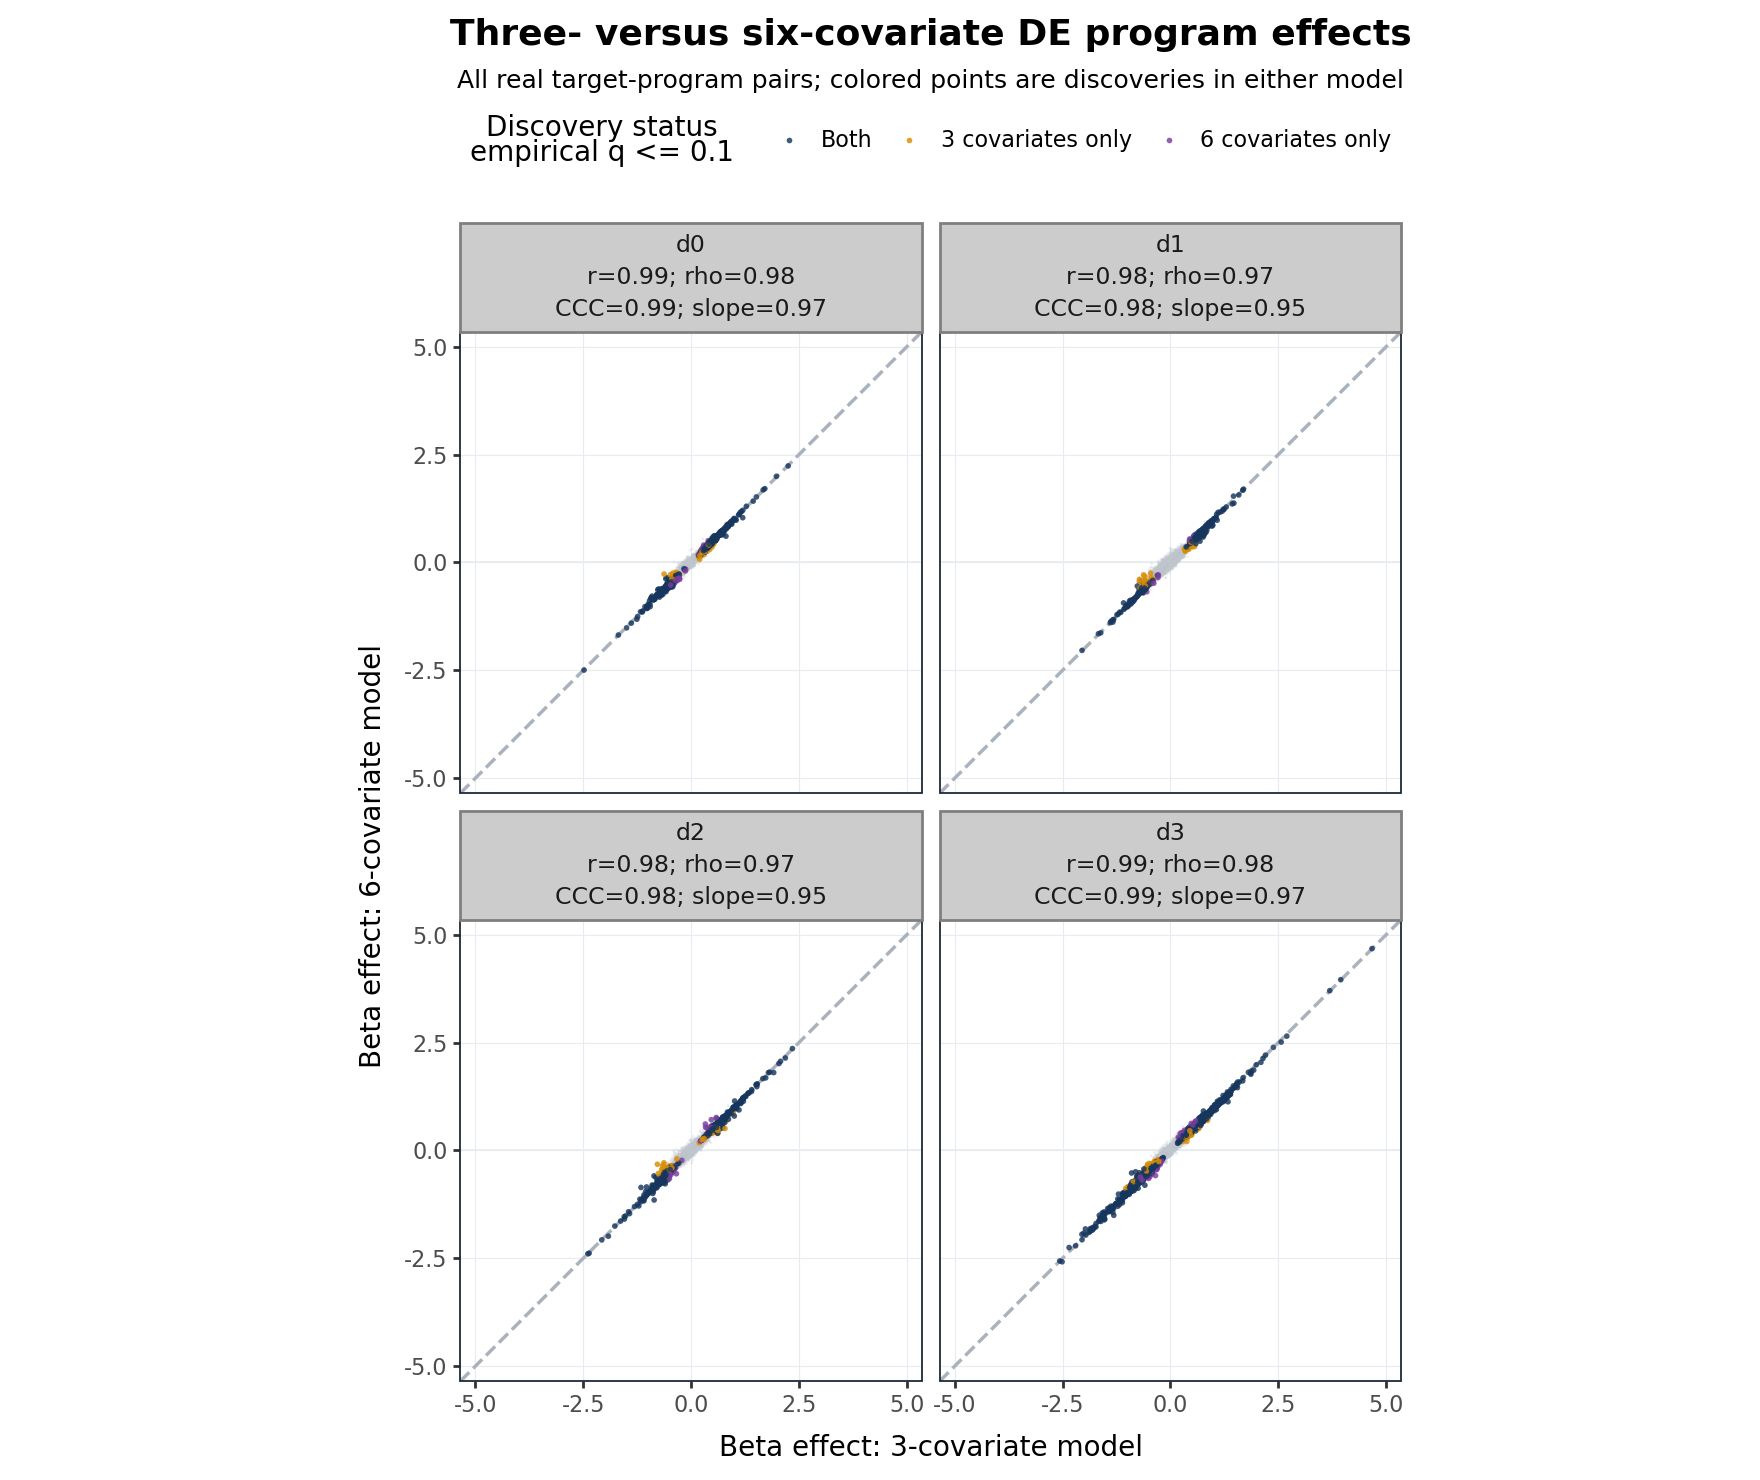

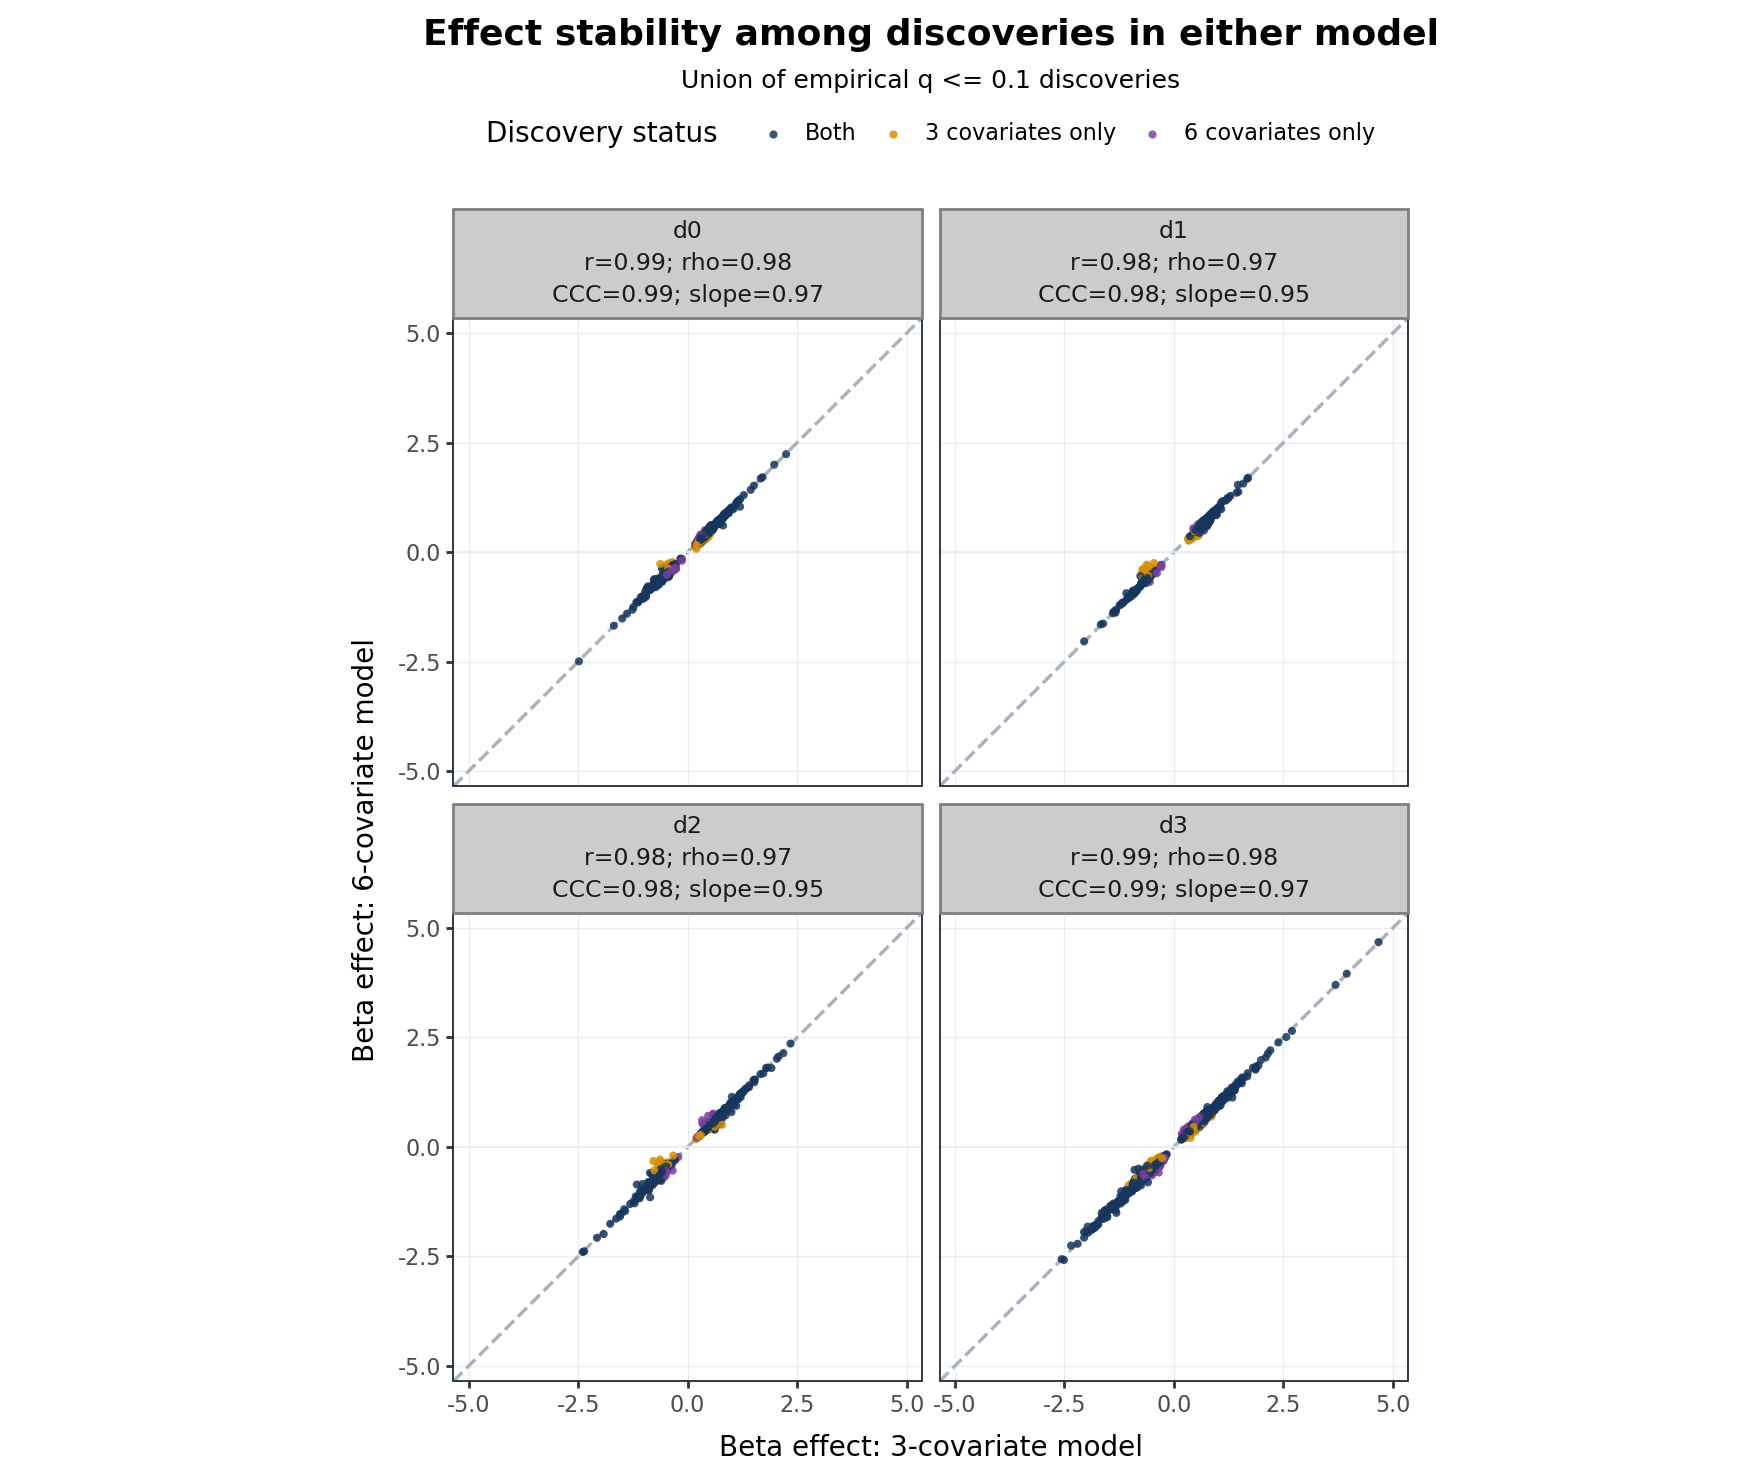

In [22]:

all_effect_metrics = effect_summary[
    effect_summary["selection"] == "all target-program pairs"
][["day", "pearson_r", "spearman_r", "concordance_correlation_coefficient", "regression_slope_6_on_3"]].copy()

all_effect_metrics["facet_label"] = all_effect_metrics.apply(
    lambda row: (
        f"{row['day']}\n"
        f"r={format_metric(row['pearson_r'])}; "
        f"rho={format_metric(row['spearman_r'])}\n"
        f"CCC={format_metric(row['concordance_correlation_coefficient'])}; "
        f"slope={format_metric(row['regression_slope_6_on_3'])}"
    ),
    axis=1,
)

beta_plot_df = paired_effects.merge(
    all_effect_metrics[["day", "facet_label"]],
    on="day",
    how="left",
)

background = beta_plot_df[beta_plot_df["discovery_status"] == "Neither"].copy()
foreground = beta_plot_df[beta_plot_df["discovery_status"] != "Neither"].copy()

beta_limit = float(
    np.nanmax(np.abs(beta_plot_df[["beta_3cov", "beta_6cov"]].to_numpy(dtype=float)))
)
beta_limit = beta_limit * 1.04 if beta_limit > 0 else 1.0

p_beta_all = (
    ggplot()
    + geom_abline(intercept=0, slope=1, linetype="dashed", color=DIAGONAL_COLOR, size=0.7)
    + geom_hline(yintercept=0, color=GRID_COLOR, size=0.35)
    + geom_point(
        data=background,
        mapping=aes("beta_3cov", "beta_6cov"),
        color=DISCOVERY_COLORS["Neither"],
        size=0.55,
        alpha=0.28,
        stroke=0,
    )
    + geom_point(
        data=foreground,
        mapping=aes("beta_3cov", "beta_6cov", color="discovery_status"),
        size=1.15,
        alpha=0.82,
        stroke=0,
    )
    + scale_color_manual(
        values=DISCOVERY_COLORS,
        breaks=["Both", "3 covariates only", "6 covariates only"],
        name=f"Discovery status\n{PRIMARY_PVALUE_TYPE_USED} q <= {PRIMARY_Q_CUTOFF}",
    )
    + facet_wrap("~facet_label", ncol=2)
    + coord_equal(xlim=(-beta_limit, beta_limit), ylim=(-beta_limit, beta_limit))
    + labs(
        title="Three- versus six-covariate DE program effects",
        subtitle="All real target-program pairs; colored points are discoveries in either model",
        x="Beta effect: 3-covariate model",
        y="Beta effect: 6-covariate model",
    )
    + theme_bw(base_size=10)
    + theme(
        figure_size=(8.8, 7.4),
        plot_title=element_text(size=13, weight="bold", ha="center"),
        plot_subtitle=element_text(size=9, ha="center"),
        strip_text=element_text(size=8.5),
        legend_position="top",
        panel_grid_major=element_line(color=GRID_COLOR, size=0.4),
        panel_grid_minor=element_blank(),
        panel_border=element_rect(color=BORDER_COLOR, size=0.65),
    )
)

display(p_beta_all)
save_plot(
    p_beta_all,
    PLOT_DIR / "beta_concordance_all_pairs_3cov_vs_6cov",
    width=8.8,
    height=7.4,
)

selected_beta_df = beta_plot_df[beta_plot_df["union_discovery"]].copy()
if not selected_beta_df.empty:
    p_beta_selected = (
        ggplot(selected_beta_df, aes("beta_3cov", "beta_6cov", color="discovery_status"))
        + geom_abline(intercept=0, slope=1, linetype="dashed", color=DIAGONAL_COLOR, size=0.7)
        + geom_hline(yintercept=0, color=GRID_COLOR, size=0.35)
        + geom_point(size=1.65, alpha=0.85, stroke=0)
        + scale_color_manual(
            values=DISCOVERY_COLORS,
            breaks=["Both", "3 covariates only", "6 covariates only"],
            name="Discovery status",
        )
        + facet_wrap("~facet_label", ncol=2)
        + coord_equal(xlim=(-beta_limit, beta_limit), ylim=(-beta_limit, beta_limit))
        + labs(
            title="Effect stability among discoveries in either model",
            subtitle=f"Union of {PRIMARY_PVALUE_TYPE_USED} q <= {PRIMARY_Q_CUTOFF} discoveries",
            x="Beta effect: 3-covariate model",
            y="Beta effect: 6-covariate model",
        )
        + theme_bw(base_size=10)
        + theme(
            figure_size=(8.8, 7.4),
            plot_title=element_text(size=13, weight="bold", ha="center"),
            plot_subtitle=element_text(size=9, ha="center"),
            strip_text=element_text(size=8.5),
            legend_position="top",
            panel_grid_major=element_line(color=GRID_COLOR, size=0.4),
            panel_grid_minor=element_blank(),
            panel_border=element_rect(color=BORDER_COLOR, size=0.65),
        )
    )
    display(p_beta_selected)
    save_plot(
        p_beta_selected,
        PLOT_DIR / "beta_concordance_union_discoveries_3cov_vs_6cov",
        width=8.8,
        height=7.4,
    )
else:
    print("No union discoveries at the primary q-value cutoff; selected-effect plot skipped.")


## 5. Bland–Altman effect-difference plot

,day,mean_beta_difference_6_minus_3,bland_altman_lower_95,bland_altman_upper_95,median_abs_beta_change,facet_label
0,d0,7.758522e-19,-0.064616,0.064616,0.013039,d0\nmean delta=0.000; median |delta|=0.013
3,d1,-1.539596e-18,-0.093214,0.093214,0.015546,d1\nmean delta=-0.000; median |delta|=0.016
6,d2,1.050241e-17,-0.091901,0.091901,0.019533,d2\nmean delta=0.000; median |delta|=0.020
9,d3,-7.870289e-19,-0.083581,0.083581,0.018212,d3\nmean delta=-0.000; median |delta|=0.018


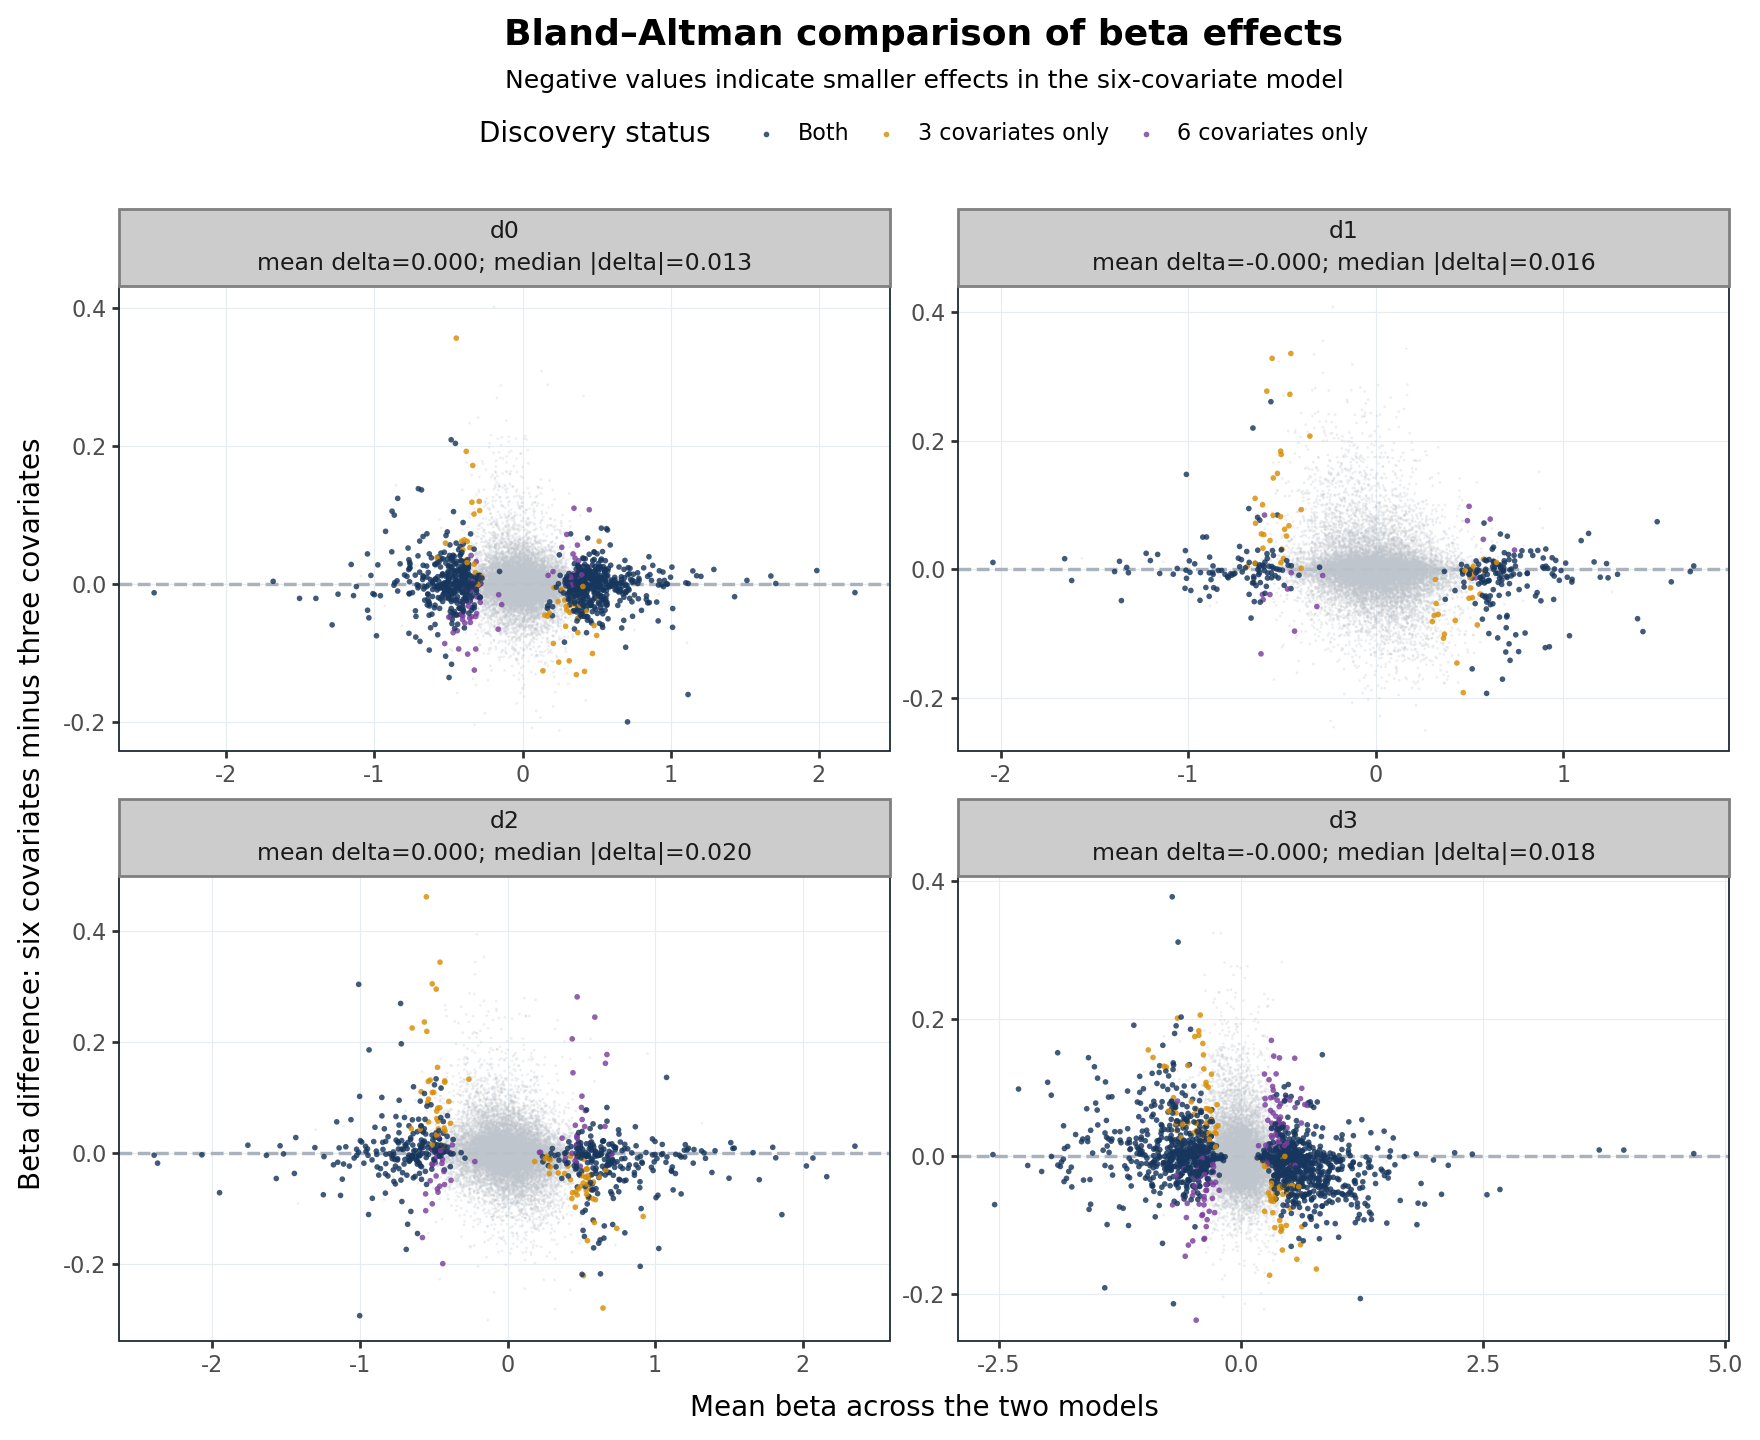

In [23]:

bland_altman_summary = (
    effect_summary[effect_summary["selection"] == "all target-program pairs"]
    [[
        "day",
        "mean_beta_difference_6_minus_3",
        "bland_altman_lower_95",
        "bland_altman_upper_95",
        "median_abs_beta_change",
    ]]
    .copy()
)

bland_altman_summary["facet_label"] = bland_altman_summary.apply(
    lambda row: (
        f"{row['day']}\n"
        f"mean delta={format_metric(row['mean_beta_difference_6_minus_3'], 3)}; "
        f"median |delta|={format_metric(row['median_abs_beta_change'], 3)}"
    ),
    axis=1,
)

ba_df = paired_effects.merge(
    bland_altman_summary[["day", "facet_label"]],
    on="day",
    how="left",
)

ba_background = ba_df[ba_df["discovery_status"] == "Neither"]
ba_foreground = ba_df[ba_df["discovery_status"] != "Neither"]

p_bland_altman = (
    ggplot()
    + geom_hline(yintercept=0, linetype="dashed", color=DIAGONAL_COLOR, size=0.7)
    + geom_point(
        data=ba_background,
        mapping=aes("beta_mean", "beta_difference_6_minus_3"),
        color=DISCOVERY_COLORS["Neither"],
        size=0.55,
        alpha=0.28,
        stroke=0,
    )
    + geom_point(
        data=ba_foreground,
        mapping=aes("beta_mean", "beta_difference_6_minus_3", color="discovery_status"),
        size=1.15,
        alpha=0.82,
        stroke=0,
    )
    + scale_color_manual(
        values=DISCOVERY_COLORS,
        breaks=["Both", "3 covariates only", "6 covariates only"],
        name="Discovery status",
    )
    + facet_wrap("~facet_label", ncol=2, scales="free")
    + labs(
        title="Bland–Altman comparison of beta effects",
        subtitle="Negative values indicate smaller effects in the six-covariate model",
        x="Mean beta across the two models",
        y="Beta difference: six covariates minus three covariates",
    )
    + theme_bw(base_size=10)
    + theme(
        figure_size=(8.8, 7.2),
        plot_title=element_text(size=13, weight="bold", ha="center"),
        plot_subtitle=element_text(size=9, ha="center"),
        strip_text=element_text(size=8.5),
        legend_position="top",
        panel_grid_major=element_line(color=GRID_COLOR, size=0.4),
        panel_grid_minor=element_blank(),
        panel_border=element_rect(color=BORDER_COLOR, size=0.65),
    )
)

display(bland_altman_summary)
display(p_bland_altman)
save_plot(
    p_bland_altman,
    PLOT_DIR / "bland_altman_beta_6cov_minus_3cov",
    width=8.8,
    height=7.2,
)

bland_altman_summary.to_csv(TABLE_DIR / "bland_altman_summary.csv", index=False)


## 6. P-value concordance and discovery-overlap plots

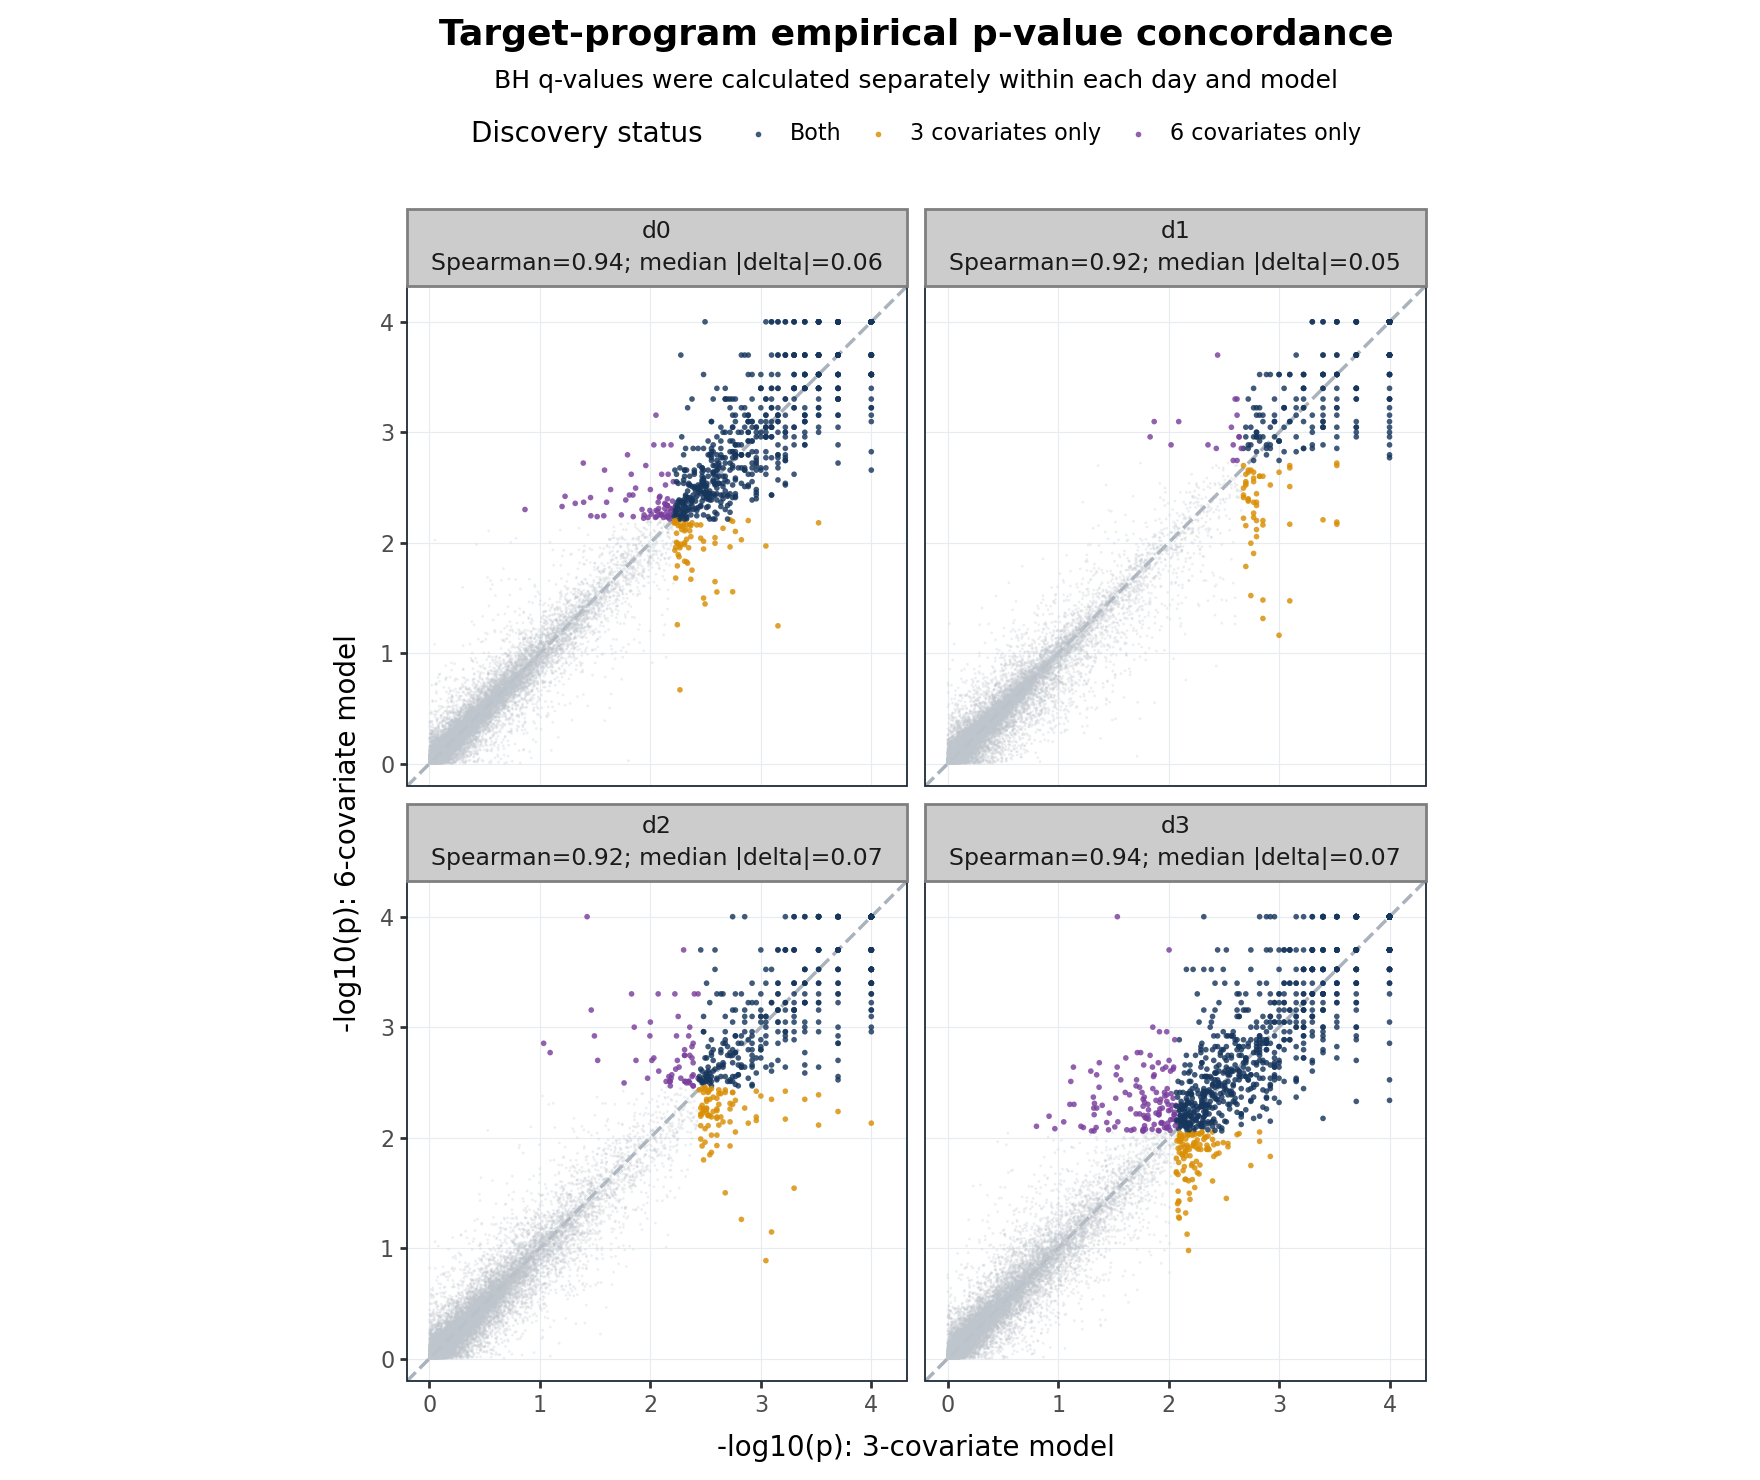

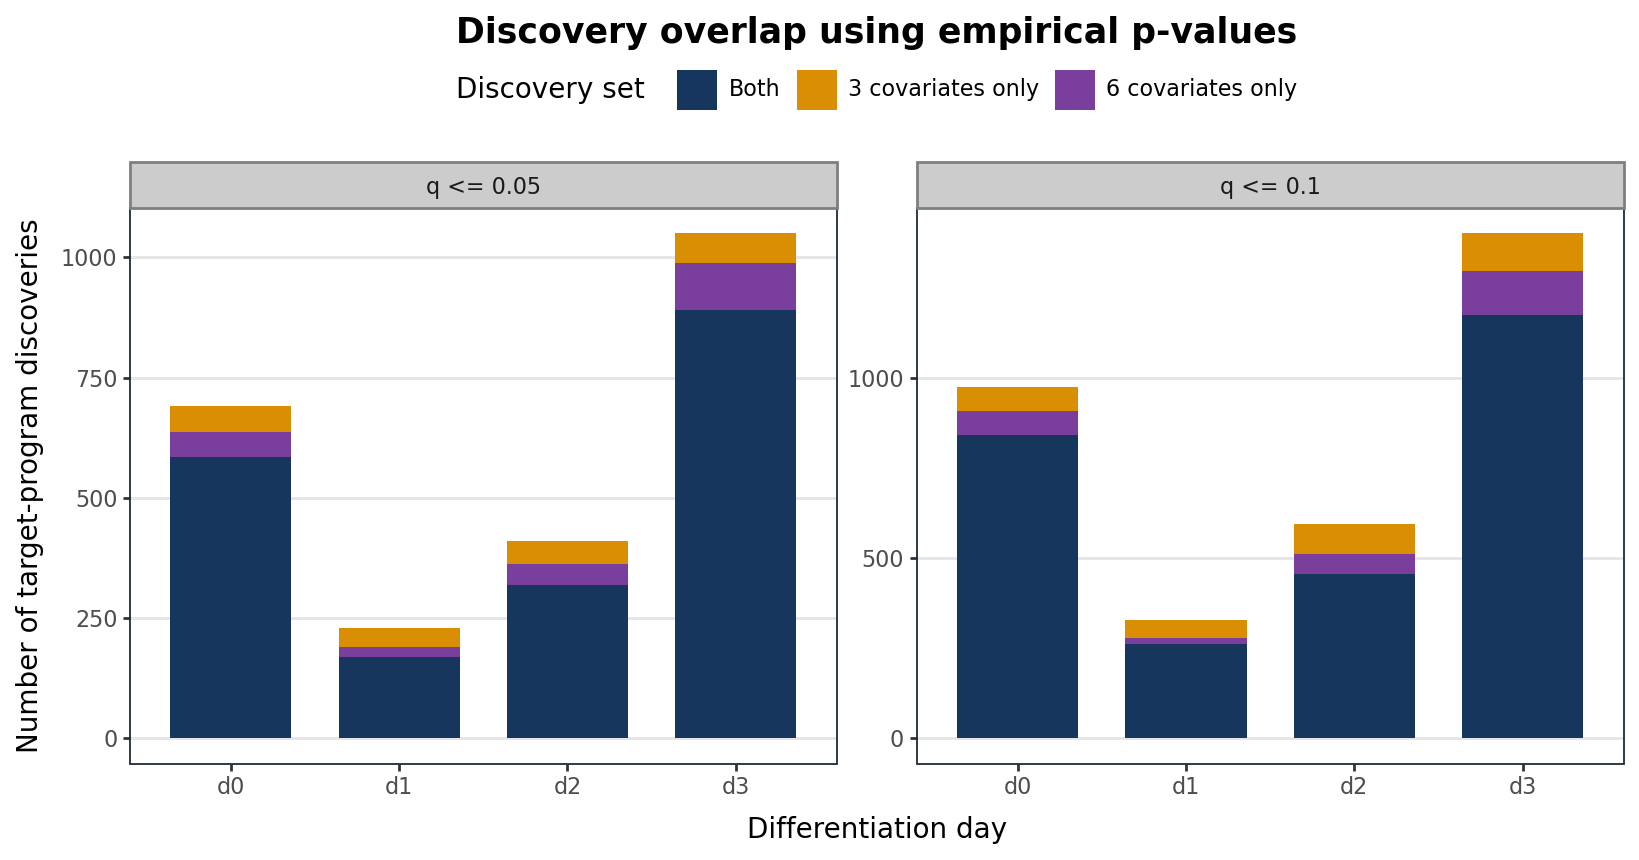

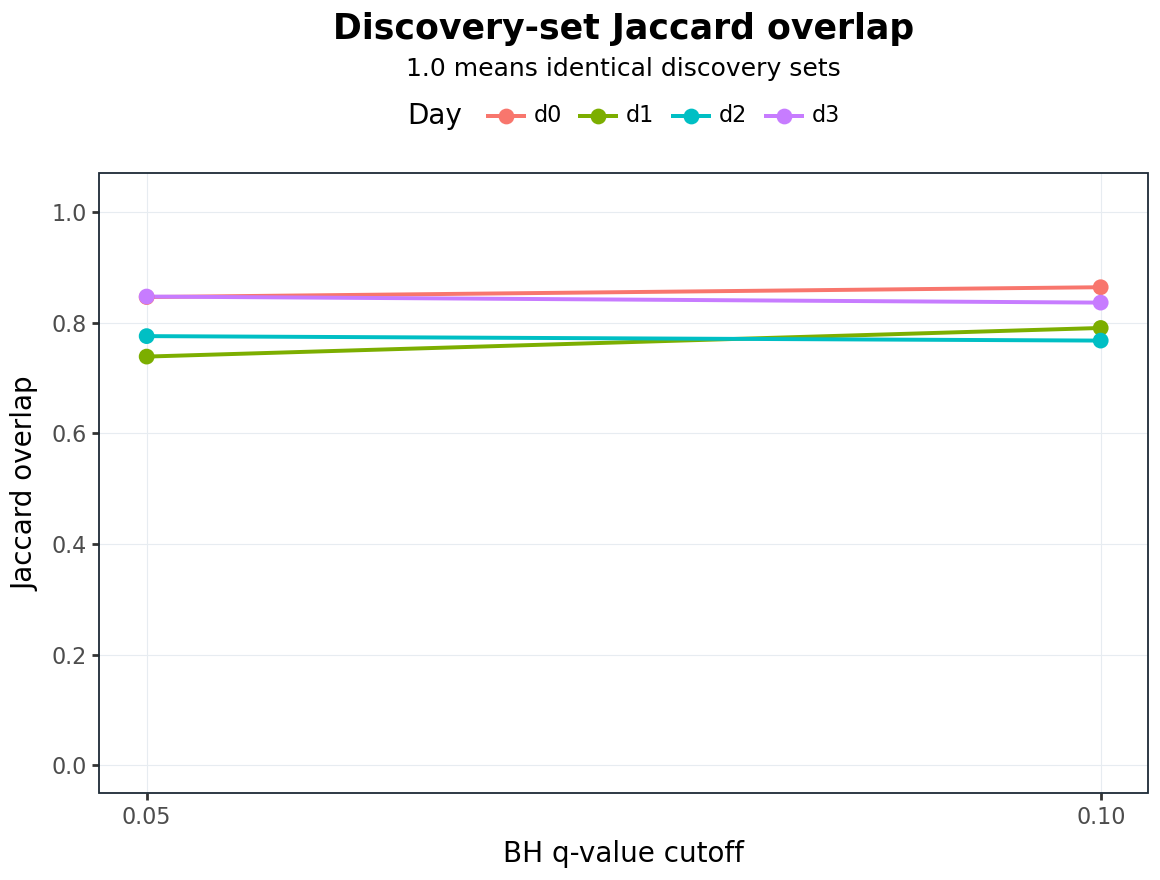

{'pdf': PosixPath('/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/QQ.sensitivity.analysis/results/ipsc_ec_3cov_vs_6cov_comparison/k_50.dt_0_2/plots/discovery_jaccard_empirical.pdf'),
 'svg': PosixPath('/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/QQ.sensitivity.analysis/results/ipsc_ec_3cov_vs_6cov_comparison/k_50.dt_0_2/plots/discovery_jaccard_empirical.svg'),
 'png': PosixPath('/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/QQ.sensitivity.analysis/results/ipsc_ec_3cov_vs_6cov_comparison/k_50.dt_0_2/plots/discovery_jaccard_empirical.png')}

In [24]:

primary_p_metrics = pvalue_summary[pvalue_summary["pvalue_type"] == PRIMARY_PVALUE_TYPE_USED].copy()
primary_p_metrics["facet_label"] = primary_p_metrics.apply(
    lambda row: (
        f"{row['day']}\n"
        f"Spearman={format_metric(row['spearman_neglog10_p'])}; "
        f"median |delta|={format_metric(row['median_abs_change_neglog10_p'], 2)}"
    ),
    axis=1,
)

pvalue_plot_df = paired_primary.merge(
    primary_p_metrics[["day", "facet_label"]],
    on="day",
    how="left",
)

pvalue_background = pvalue_plot_df[pvalue_plot_df["discovery_status"] == "Neither"]
pvalue_foreground = pvalue_plot_df[pvalue_plot_df["discovery_status"] != "Neither"]

pvalue_limit = float(
    np.nanmax(
        pvalue_plot_df[["neglog10_p_3cov", "neglog10_p_6cov"]].to_numpy(dtype=float)
    )
)
pvalue_limit = max(1.0, pvalue_limit * 1.03)

p_pvalue = (
    ggplot()
    + geom_abline(intercept=0, slope=1, linetype="dashed", color=DIAGONAL_COLOR, size=0.7)
    + geom_point(
        data=pvalue_background,
        mapping=aes("neglog10_p_3cov", "neglog10_p_6cov"),
        color=DISCOVERY_COLORS["Neither"],
        size=0.55,
        alpha=0.28,
        stroke=0,
    )
    + geom_point(
        data=pvalue_foreground,
        mapping=aes("neglog10_p_3cov", "neglog10_p_6cov", color="discovery_status"),
        size=1.15,
        alpha=0.82,
        stroke=0,
    )
    + scale_color_manual(
        values=DISCOVERY_COLORS,
        breaks=["Both", "3 covariates only", "6 covariates only"],
        name="Discovery status",
    )
    + facet_wrap("~facet_label", ncol=2)
    + coord_equal(xlim=(0, pvalue_limit), ylim=(0, pvalue_limit))
    + labs(
        title=f"Target-program {PRIMARY_PVALUE_TYPE_USED} p-value concordance",
        subtitle="BH q-values were calculated separately within each day and model",
        x="-log10(p): 3-covariate model",
        y="-log10(p): 6-covariate model",
    )
    + theme_bw(base_size=10)
    + theme(
        figure_size=(8.8, 7.4),
        plot_title=element_text(size=13, weight="bold", ha="center"),
        plot_subtitle=element_text(size=9, ha="center"),
        strip_text=element_text(size=8.5),
        legend_position="top",
        panel_grid_major=element_line(color=GRID_COLOR, size=0.4),
        panel_grid_minor=element_blank(),
        panel_border=element_rect(color=BORDER_COLOR, size=0.65),
    )
)

display(p_pvalue)
save_plot(
    p_pvalue,
    PLOT_DIR / f"pvalue_concordance_{PRIMARY_PVALUE_TYPE_USED}_3cov_vs_6cov",
    width=8.8,
    height=7.4,
)

primary_discovery = discovery_summary[
    discovery_summary["pvalue_type"] == PRIMARY_PVALUE_TYPE_USED
].copy()
primary_discovery["q_label"] = primary_discovery["q_cutoff"].map(lambda x: f"q <= {x:g}")

discovery_count_plot = primary_discovery.melt(
    id_vars=["day", "q_label"],
    value_vars=["n_intersection", "n_3cov_only", "n_6cov_only"],
    var_name="category_code",
    value_name="n_discoveries",
)
discovery_count_plot["category"] = discovery_count_plot["category_code"].map({
    "n_intersection": "Both",
    "n_3cov_only": "3 covariates only",
    "n_6cov_only": "6 covariates only",
})

p_discovery_counts = (
    ggplot(discovery_count_plot, aes("day", "n_discoveries", fill="category"))
    + geom_col(position="stack", width=0.72)
    + scale_fill_manual(
        values=DISCOVERY_COLORS,
        breaks=["Both", "3 covariates only", "6 covariates only"],
        name="Discovery set",
    )
    + facet_wrap("~q_label", nrow=1, scales="free_y")
    + labs(
        title=f"Discovery overlap using {PRIMARY_PVALUE_TYPE_USED} p-values",
        x="Differentiation day",
        y="Number of target-program discoveries",
    )
    + theme_bw(base_size=10)
    + theme(
        figure_size=(8.2, 4.3),
        plot_title=element_text(size=12.5, weight="bold", ha="center"),
        legend_position="top",
        panel_grid_major_x=element_blank(),
        panel_grid_minor=element_blank(),
        panel_border=element_rect(color=BORDER_COLOR, size=0.65),
    )
)

display(p_discovery_counts)
save_plot(
    p_discovery_counts,
    PLOT_DIR / f"discovery_overlap_counts_{PRIMARY_PVALUE_TYPE_USED}",
    width=8.2,
    height=4.3,
)

p_jaccard = (
    ggplot(primary_discovery, aes("q_cutoff", "jaccard", color="day", group="day"))
    + geom_line(size=0.8)
    + geom_point(size=2.2)
    + scale_x_continuous(breaks=Q_CUTOFFS)
    + scale_y_continuous(limits=(0, 1.02), breaks=np.arange(0, 1.01, 0.2))
    + labs(
        title="Discovery-set Jaccard overlap",
        subtitle="1.0 means identical discovery sets",
        x="BH q-value cutoff",
        y="Jaccard overlap",
        color="Day",
    )
    + theme_bw(base_size=10)
    + theme(
        figure_size=(5.8, 4.4),
        plot_title=element_text(size=12.5, weight="bold", ha="center"),
        plot_subtitle=element_text(size=9, ha="center"),
        legend_position="top",
        panel_grid_major=element_line(color=GRID_COLOR, size=0.4),
        panel_grid_minor=element_blank(),
        panel_border=element_rect(color=BORDER_COLOR, size=0.65),
    )
)

display(p_jaccard)
save_plot(
    p_jaccard,
    PLOT_DIR / f"discovery_jaccard_{PRIMARY_PVALUE_TYPE_USED}",
    width=5.8,
    height=4.4,
)



## 7. NTC pseudo-target calibration comparison

The NTC metrics assess how close each model's pseudo-target p-values are to Uniform(0,1). Because pseudo-target tests can be dependent, the notebook reports the **KS distance** but not the nominal KS test p-value. Smaller absolute type-I-error deviation, QQ RMSE, tail QQ RMSE, and KS distance indicate better calibration.


NTC calibration metrics:


,model,model_label,day,pvalue_type,n_pvalues,median_p,mean_p,fraction_p_lt_0_01,fraction_p_lt_0_05,fraction_p_lt_0_10,abs_error_at_0_05,ks_distance,qq_rmse,qq_tail_rmse,qq_max_abs_error
0,3cov,3 covariates,d0,skew,6100,0.481423,0.485957,0.014426,0.066557,0.120984,0.016557,0.028772,0.051865,0.131762,0.614255
1,3cov,3 covariates,d0,empirical,6100,0.488101,0.490848,0.012623,0.058689,0.115902,0.008689,0.019583,0.034047,0.103845,0.390805
2,3cov,3 covariates,d1,skew,4650,0.493024,0.489781,0.010538,0.055484,0.110753,0.005484,0.021607,0.027877,0.097651,0.413581
3,3cov,3 covariates,d1,empirical,4650,0.491201,0.491911,0.012043,0.057634,0.110753,0.007634,0.014934,0.025003,0.066921,0.253409
4,3cov,3 covariates,d2,skew,6350,0.497277,0.498032,0.008504,0.047874,0.098425,0.002126,0.012381,0.015109,0.117914,0.301757
5,3cov,3 covariates,d2,empirical,6350,0.495350,0.499482,0.010079,0.050551,0.102047,0.000551,0.007165,0.008298,0.071362,0.294180
6,3cov,3 covariates,d3,skew,7750,0.454629,0.468736,0.024774,0.083097,0.137161,0.033097,0.054644,0.146971,0.874913,1.868127
7,3cov,3 covariates,d3,empirical,7750,0.504050,0.501486,0.011613,0.051355,0.099355,0.001355,0.007520,0.015856,0.148521,0.286833
8,6cov,6 covariates,d0,skew,6100,0.479589,0.484979,0.013934,0.065574,0.125738,0.015574,0.032366,0.056529,0.200015,0.947160
9,6cov,6 covariates,d0,empirical,6100,0.487051,0.491186,0.012295,0.059672,0.116066,0.009672,0.020224,0.033298,0.111614,0.457752



Paired NTC p-value concordance:


,day,pvalue_type,n_3cov,n_6cov,n_matched,match_fraction,pearson_neglog10_p,spearman_neglog10_p
0,d0,skew,6100,6100,6100,1.0,0.971321,0.953820
1,d0,empirical,6100,6100,6100,1.0,0.948967,0.910579
2,d1,skew,4650,4650,4650,1.0,0.960747,0.936049
3,d1,empirical,4650,4650,4650,1.0,0.951259,0.919436
4,d2,skew,6350,6350,6350,1.0,0.973643,0.954965
5,d2,empirical,6350,6350,6350,1.0,0.963174,0.934492
6,d3,skew,7750,7750,7750,1.0,0.978109,0.958028
7,d3,empirical,7750,7750,7750,1.0,0.958961,0.932483


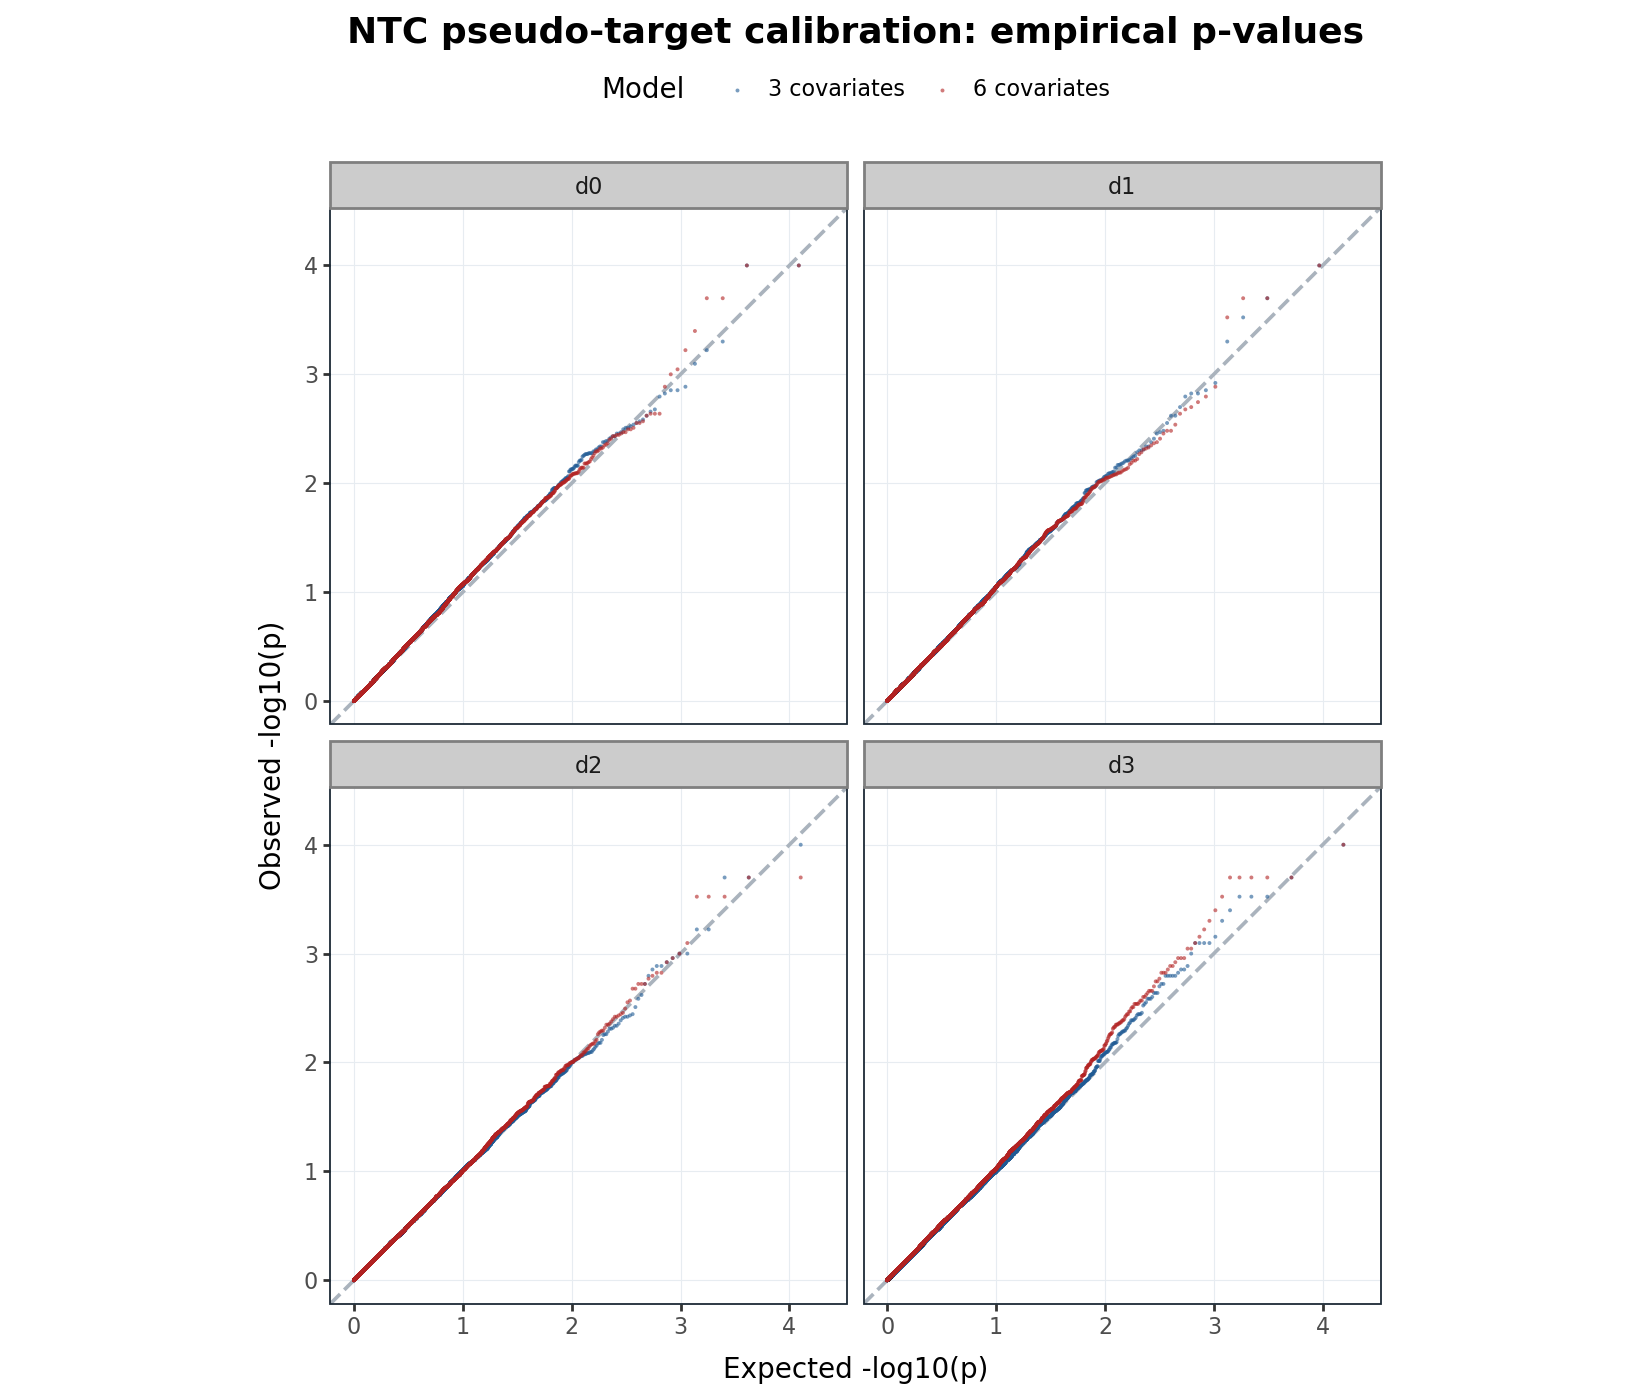

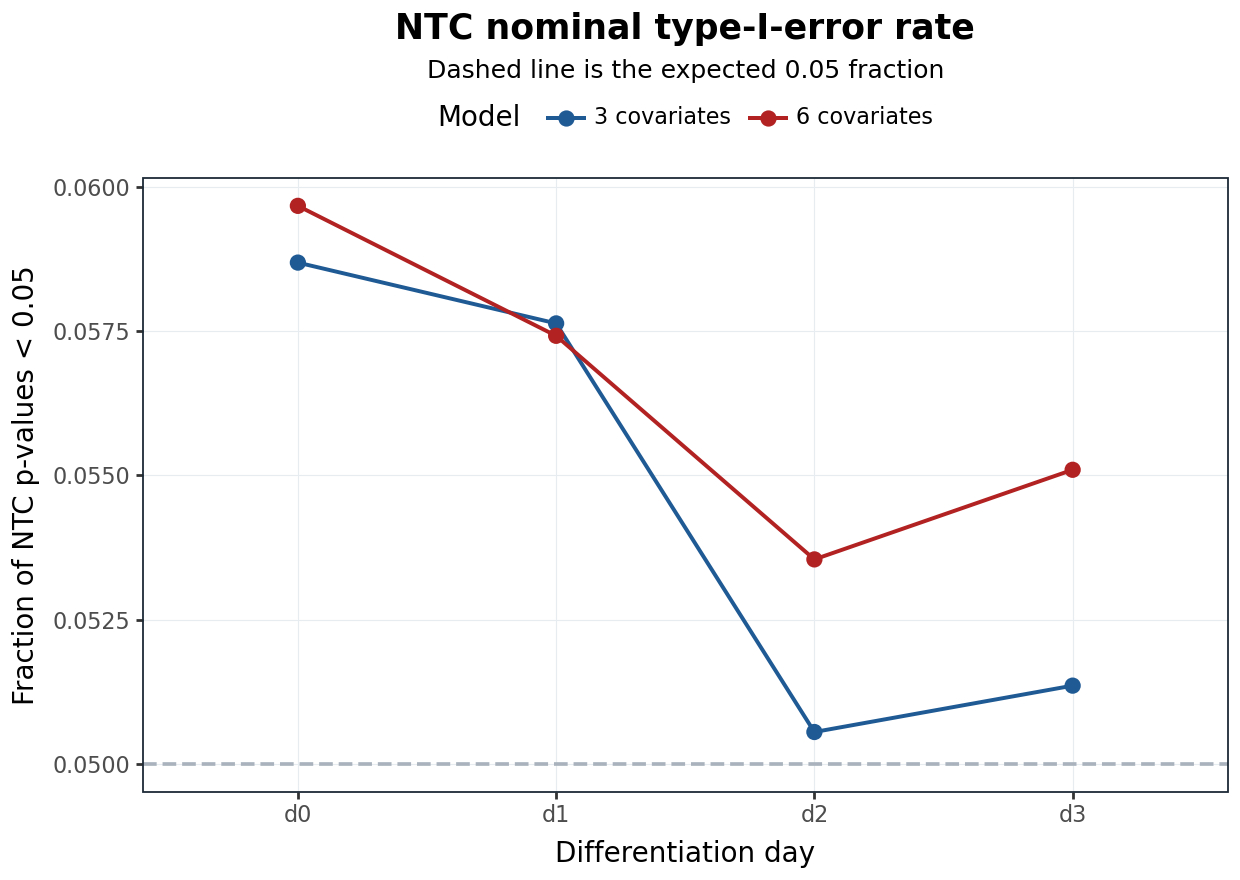

In [25]:

ntc_tables = []
for model_code, root in MODEL_ROOTS.items():
    for day in DAYS:
        paths = paths_by_model_day[(model_code, day)]
        for pvalue_type in ntc_pvalue_types:
            current = read_ntc_wide(paths[f"ntc_{pvalue_type}"])
            current.insert(0, "pvalue_type", pvalue_type)
            current.insert(0, "day", day)
            current.insert(0, "model_label", MODEL_LABELS[model_code])
            current.insert(0, "model", model_code)
            ntc_tables.append(current)

ntc_long = pd.concat(ntc_tables, ignore_index=True, sort=False)

ntc_metric_rows = []
for (model_code, model_label, day, pvalue_type), group in ntc_long.groupby(
    ["model", "model_label", "day", "pvalue_type"],
    sort=False,
):
    ntc_metric_rows.append({
        "model": model_code,
        "model_label": model_label,
        "day": day,
        "pvalue_type": pvalue_type,
        **uniform_calibration_metrics(group["pvalue"]),
    })
ntc_calibration_summary = pd.DataFrame(ntc_metric_rows)

# Pair the same ensemble/group/program pseudo-target tests across models.
ntc_pair_rows = []
for day in DAYS:
    for pvalue_type in ntc_pvalue_types:
        left = ntc_long[
            (ntc_long["model"] == "3cov")
            & (ntc_long["day"] == day)
            & (ntc_long["pvalue_type"] == pvalue_type)
        ].rename(columns={"pvalue": "pvalue_3cov"})
        right = ntc_long[
            (ntc_long["model"] == "6cov")
            & (ntc_long["day"] == day)
            & (ntc_long["pvalue_type"] == pvalue_type)
        ].rename(columns={"pvalue": "pvalue_6cov"})

        id_columns = [c for c in ["ensemble", "group_id", "program_name"] if c in left.columns and c in right.columns]
        joined = left[id_columns + ["pvalue_3cov"]].merge(
            right[id_columns + ["pvalue_6cov"]],
            on=id_columns,
            how="outer",
            indicator=True,
            validate="one_to_one",
        )
        matched = joined[joined["_merge"] == "both"].copy()
        ntc_pair_rows.append({
            "day": day,
            "pvalue_type": pvalue_type,
            "n_3cov": len(left),
            "n_6cov": len(right),
            "n_matched": len(matched),
            "match_fraction": float((joined["_merge"] == "both").mean()),
            "pearson_neglog10_p": safe_pearson(
                -np.log10(matched["pvalue_3cov"].clip(1e-300, 1.0)),
                -np.log10(matched["pvalue_6cov"].clip(1e-300, 1.0)),
            ),
            "spearman_neglog10_p": safe_spearman(
                -np.log10(matched["pvalue_3cov"].clip(1e-300, 1.0)),
                -np.log10(matched["pvalue_6cov"].clip(1e-300, 1.0)),
            ),
        })
ntc_between_model_summary = pd.DataFrame(ntc_pair_rows)

print("NTC calibration metrics:")
display(ntc_calibration_summary)

print("\nPaired NTC p-value concordance:")
display(ntc_between_model_summary)

# Build QQ coordinates independently for each model/day.
qq_frames = []
for (model_code, model_label, day), group in ntc_long[
    ntc_long["pvalue_type"] == PRIMARY_NTC_PVALUE_TYPE_USED
].groupby(["model", "model_label", "day"], sort=False):
    points = qq_points(group["pvalue"])
    points["model"] = model_code
    points["model_label"] = model_label
    points["day"] = day
    qq_frames.append(points)
ntc_qq = pd.concat(qq_frames, ignore_index=True)

ntc_qq_limit = float(
    np.nanmax(
        ntc_qq[["expected_neglog10_p", "observed_neglog10_p"]].to_numpy(dtype=float)
    )
)
ntc_qq_limit = max(1.0, ntc_qq_limit * 1.03)

p_ntc_qq = (
    ggplot(ntc_qq, aes("expected_neglog10_p", "observed_neglog10_p", color="model_label"))
    + geom_abline(intercept=0, slope=1, linetype="dashed", color=DIAGONAL_COLOR, size=0.75)
    + geom_point(size=0.8, alpha=0.60, stroke=0)
    + scale_color_manual(values=MODEL_COLORS, name="Model")
    + facet_wrap("~day", ncol=2)
    + coord_equal(xlim=(0, ntc_qq_limit), ylim=(0, ntc_qq_limit))
    + labs(
        title=f"NTC pseudo-target calibration: {PRIMARY_NTC_PVALUE_TYPE_USED} p-values",
        x="Expected -log10(p)",
        y="Observed -log10(p)",
    )
    + theme_bw(base_size=10)
    + theme(
        figure_size=(8.2, 7.0),
        plot_title=element_text(size=13, weight="bold", ha="center"),
        legend_position="top",
        panel_grid_major=element_line(color=GRID_COLOR, size=0.4),
        panel_grid_minor=element_blank(),
        panel_border=element_rect(color=BORDER_COLOR, size=0.65),
    )
)

display(p_ntc_qq)
save_plot(
    p_ntc_qq,
    PLOT_DIR / f"NTC_QQ_3cov_vs_6cov_{PRIMARY_NTC_PVALUE_TYPE_USED}",
    width=8.2,
    height=7.0,
)

ntc_primary_metrics = ntc_calibration_summary[
    ntc_calibration_summary["pvalue_type"] == PRIMARY_NTC_PVALUE_TYPE_USED
].copy()

p_ntc_type1 = (
    ggplot(ntc_primary_metrics, aes("day", "fraction_p_lt_0_05", color="model_label", group="model_label"))
    + geom_hline(yintercept=0.05, linetype="dashed", color=DIAGONAL_COLOR, size=0.75)
    + geom_line(size=0.8)
    + geom_point(size=2.3)
    + scale_color_manual(values=MODEL_COLORS, name="Model")
    + labs(
        title="NTC nominal type-I-error rate",
        subtitle="Dashed line is the expected 0.05 fraction",
        x="Differentiation day",
        y="Fraction of NTC p-values < 0.05",
    )
    + theme_bw(base_size=10)
    + theme(
        figure_size=(6.2, 4.4),
        plot_title=element_text(size=12.5, weight="bold", ha="center"),
        plot_subtitle=element_text(size=9, ha="center"),
        legend_position="top",
        panel_grid_major=element_line(color=GRID_COLOR, size=0.4),
        panel_grid_minor=element_blank(),
        panel_border=element_rect(color=BORDER_COLOR, size=0.65),
    )
)

display(p_ntc_type1)
save_plot(
    p_ntc_type1,
    PLOT_DIR / f"NTC_fraction_p_lt_0_05_{PRIMARY_NTC_PVALUE_TYPE_USED}",
    width=6.2,
    height=4.4,
)

ntc_long.to_csv(TABLE_DIR / "NTC_pvalues_long.csv", index=False)
ntc_calibration_summary.to_csv(TABLE_DIR / "NTC_calibration_summary.csv", index=False)
ntc_between_model_summary.to_csv(TABLE_DIR / "NTC_between_model_concordance.csv", index=False)


## 8. Program- and target-level heterogeneity

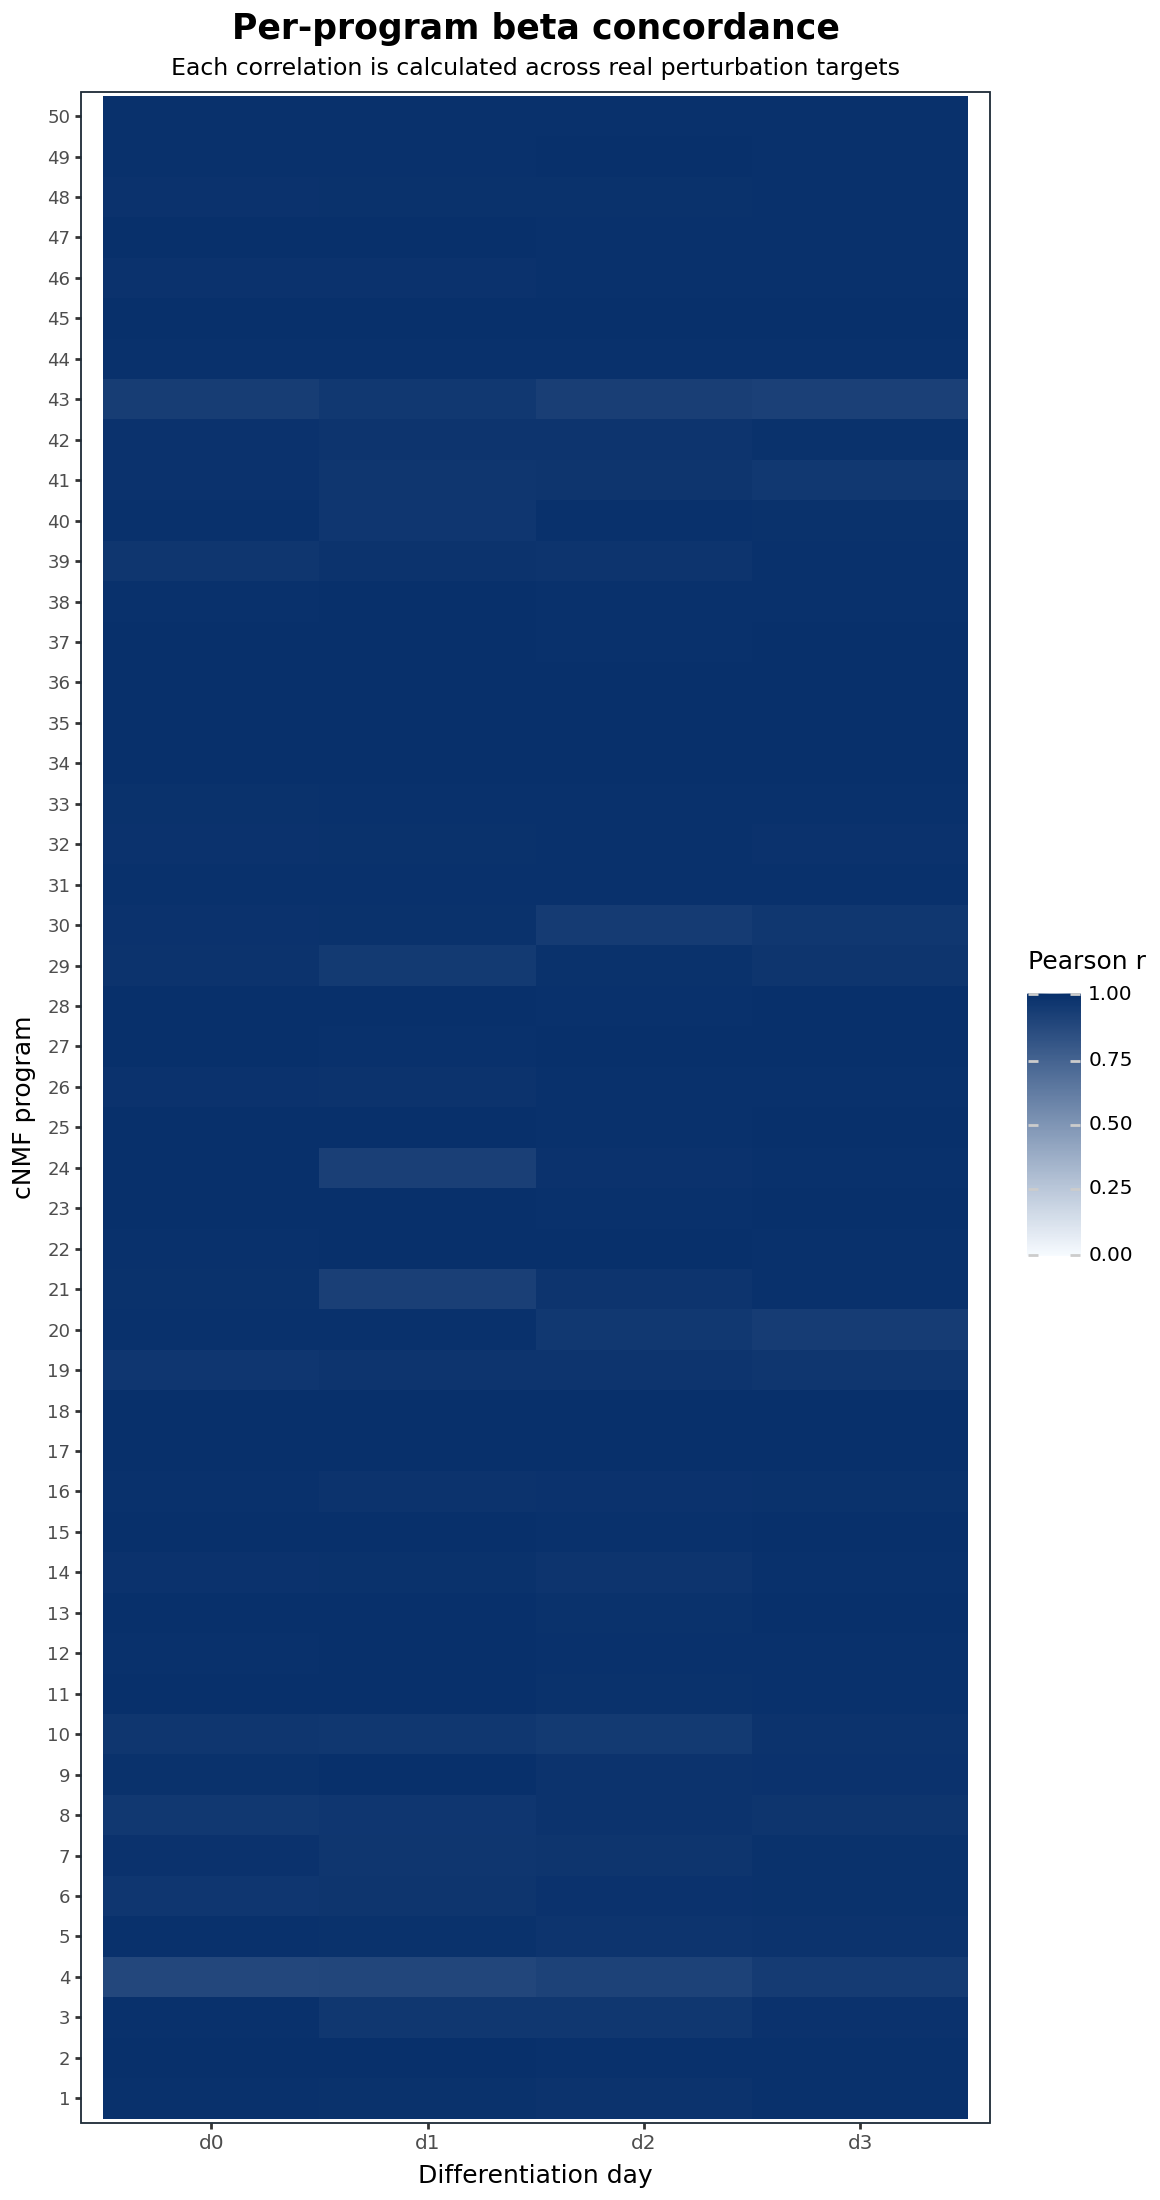

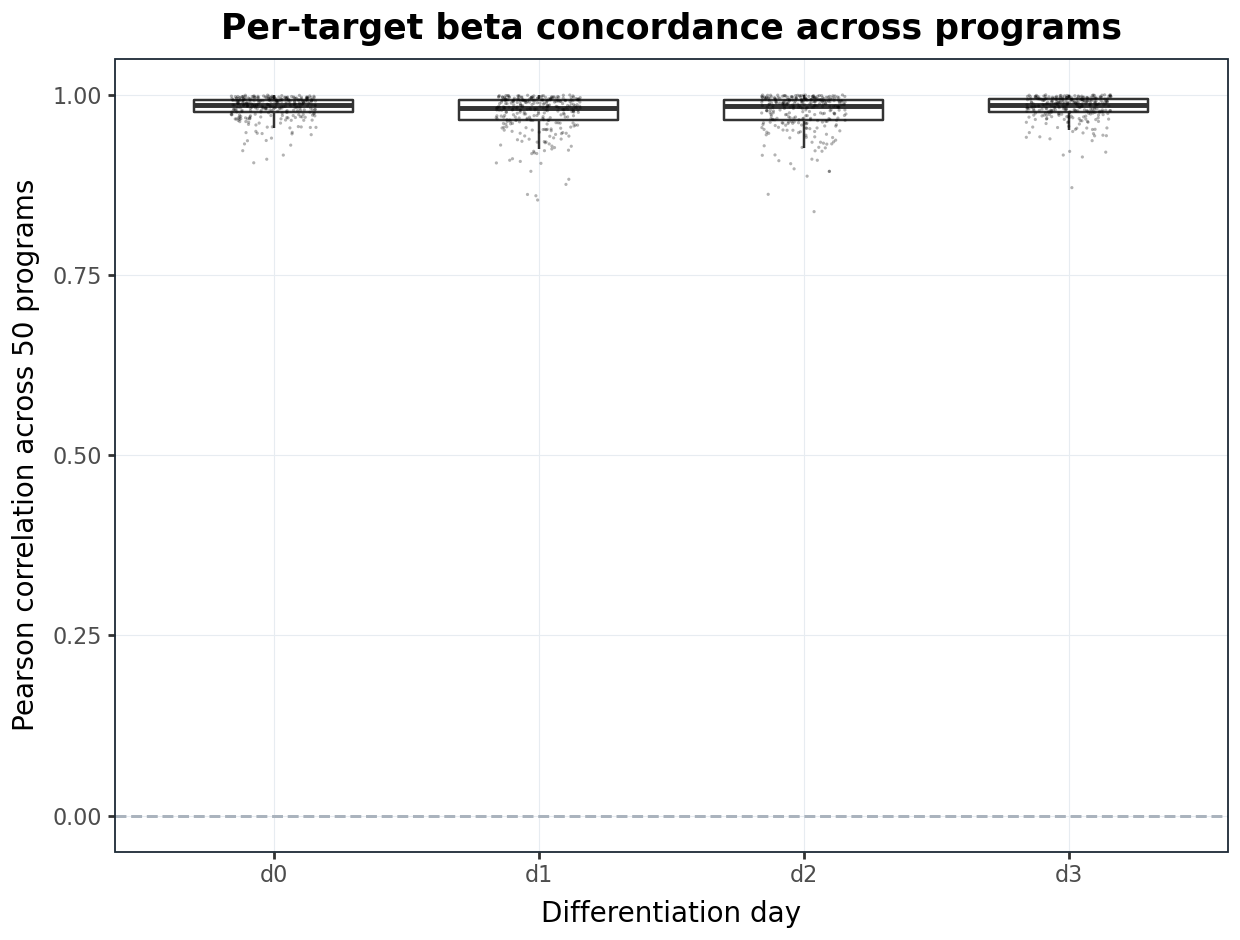

Worst 10 programs per day by beta Pearson correlation:


,day,program_name,n_targets,pearson_r,spearman_r,ccc,median_abs_beta_change,median_abs_beta_3cov,median_abs_beta_6cov,sign_concordance,program_factor
33,d0,4,298,0.885130,0.888732,0.765557,0.095897,0.153744,0.095388,0.788591,4
37,d0,43,298,0.938135,0.929020,0.932756,0.028363,0.089048,0.085683,0.882550,43
48,d0,8,298,0.959877,0.927105,0.941772,0.041915,0.096868,0.083893,0.852349,8
46,d0,6,298,0.967870,0.953882,0.938498,0.029582,0.067302,0.057868,0.879195,6
10,d0,19,298,0.968745,0.961429,0.959920,0.035990,0.123363,0.115287,0.906040,19
32,d0,39,298,0.971243,0.966202,0.932186,0.054039,0.106164,0.125840,0.855705,39
1,d0,10,298,0.973391,0.969991,0.973097,0.023962,0.100107,0.097286,0.942953,10
21,d0,29,298,0.982988,0.979725,0.981854,0.021449,0.114264,0.112996,0.932886,29
42,d0,48,298,0.986295,0.981690,0.980476,0.017687,0.080327,0.082807,0.926174,48
23,d0,30,298,0.986452,0.983431,0.978507,0.028141,0.119962,0.112570,0.946309,30



Worst 20 targets per day by beta Pearson correlation:


,day,target_name,n_programs,pearson_r,spearman_r,ccc,median_abs_beta_change,median_abs_beta_3cov,median_abs_beta_6cov,sign_concordance
41,d0,CDKN1A,50,0.905701,0.886291,0.894642,0.021530,0.069079,0.054390,0.82
271,d0,TMTC3,50,0.910639,0.898776,0.910459,0.027778,0.105397,0.110070,0.90
283,d0,VWA9,50,0.916379,0.864970,0.916130,0.043972,0.165201,0.161815,0.92
54,d0,DACH1,50,0.922493,0.912989,0.921949,0.019735,0.071352,0.071738,0.92
201,d0,RGP1,50,0.930190,0.946603,0.924131,0.029238,0.116972,0.095833,0.94
...,...,...,...,...,...,...,...,...,...,...
1052,d3,PAM16,50,0.949126,0.952365,0.943840,0.029040,0.125843,0.106799,0.96
956,d3,DPM2,50,0.951858,0.942377,0.951694,0.029707,0.093090,0.085632,0.96
924,d3,CAPN5,50,0.952119,0.936807,0.952107,0.024591,0.091253,0.084388,0.92
916,d3,BRD3,50,0.952133,0.950636,0.947952,0.028349,0.084055,0.097658,0.90


In [26]:

program_rows = []
for (day, program_name), group in paired_effects.groupby(["day", "program_name"], sort=False):
    program_rows.append({
        "day": day,
        "program_name": str(program_name),
        "n_targets": len(group),
        "pearson_r": safe_pearson(group["beta_3cov"], group["beta_6cov"]),
        "spearman_r": safe_spearman(group["beta_3cov"], group["beta_6cov"]),
        "ccc": concordance_correlation_coefficient(group["beta_3cov"], group["beta_6cov"]),
        "median_abs_beta_change": float(np.median(np.abs(group["beta_difference_6_minus_3"]))),
        "median_abs_beta_3cov": float(np.median(group["abs_beta_3cov"])),
        "median_abs_beta_6cov": float(np.median(group["abs_beta_6cov"])),
        "sign_concordance": float(group["sign_concordant"].mean()),
    })
program_summary = pd.DataFrame(program_rows)

target_rows = []
for (day, target_name), group in paired_effects.groupby(["day", "target_name"], sort=False):
    target_rows.append({
        "day": day,
        "target_name": str(target_name),
        "n_programs": len(group),
        "pearson_r": safe_pearson(group["beta_3cov"], group["beta_6cov"]),
        "spearman_r": safe_spearman(group["beta_3cov"], group["beta_6cov"]),
        "ccc": concordance_correlation_coefficient(group["beta_3cov"], group["beta_6cov"]),
        "median_abs_beta_change": float(np.median(np.abs(group["beta_difference_6_minus_3"]))),
        "median_abs_beta_3cov": float(np.median(group["abs_beta_3cov"])),
        "median_abs_beta_6cov": float(np.median(group["abs_beta_6cov"])),
        "sign_concordance": float(group["sign_concordant"].mean()),
    })
target_summary = pd.DataFrame(target_rows)

program_order = sorted(program_summary["program_name"].unique(), key=natural_sort_key)
program_summary["program_factor"] = pd.Categorical(
    program_summary["program_name"],
    categories=program_order,
    ordered=True,
)

p_program_heatmap = (
    ggplot(program_summary, aes("day", "program_factor", fill="pearson_r"))
    + geom_tile()
    + scale_fill_gradient(
        low="#F7FBFF",
        high="#08306B",
        limits=(0, 1),
        name="Pearson r",
    )
    + labs(
        title="Per-program beta concordance",
        subtitle="Each correlation is calculated across real perturbation targets",
        x="Differentiation day",
        y="cNMF program",
    )
    + theme_bw(base_size=9)
    + theme(
        figure_size=(5.8, 11.0),
        plot_title=element_text(size=12.5, weight="bold", ha="center"),
        plot_subtitle=element_text(size=8.5, ha="center"),
        axis_text_y=element_text(size=6.5),
        panel_grid=element_blank(),
        panel_border=element_rect(color=BORDER_COLOR, size=0.65),
    )
)

display(p_program_heatmap)
save_plot(
    p_program_heatmap,
    PLOT_DIR / "program_level_beta_pearson_heatmap",
    width=5.8,
    height=11.0,
)

p_target_distribution = (
    ggplot(target_summary, aes("day", "pearson_r"))
    + geom_boxplot(outlier_alpha=0, width=0.60)
    + geom_jitter(width=0.16, height=0, size=0.65, alpha=0.30, stroke=0)
    + geom_hline(yintercept=0, linetype="dashed", color=DIAGONAL_COLOR, size=0.6)
    + labs(
        title="Per-target beta concordance across programs",
        x="Differentiation day",
        y="Pearson correlation across 50 programs",
    )
    + theme_bw(base_size=10)
    + theme(
        figure_size=(6.2, 4.7),
        plot_title=element_text(size=12.5, weight="bold", ha="center"),
        panel_grid_major=element_line(color=GRID_COLOR, size=0.4),
        panel_grid_minor=element_blank(),
        panel_border=element_rect(color=BORDER_COLOR, size=0.65),
    )
)

display(p_target_distribution)
save_plot(
    p_target_distribution,
    PLOT_DIR / "target_level_beta_correlation_distribution",
    width=6.2,
    height=4.7,
)

worst_programs = (
    program_summary
    .sort_values(["day", "pearson_r"], ascending=[True, True])
    .groupby("day", sort=False)
    .head(10)
)
worst_targets = (
    target_summary
    .sort_values(["day", "pearson_r"], ascending=[True, True])
    .groupby("day", sort=False)
    .head(20)
)

print("Worst 10 programs per day by beta Pearson correlation:")
display(worst_programs)

print("\nWorst 20 targets per day by beta Pearson correlation:")
display(worst_targets)

program_summary.to_csv(TABLE_DIR / "program_level_effect_concordance.csv", index=False)
target_summary.to_csv(TABLE_DIR / "target_level_effect_concordance.csv", index=False)
worst_programs.to_csv(TABLE_DIR / "worst_programs_by_effect_concordance.csv", index=False)
worst_targets.to_csv(TABLE_DIR / "worst_targets_by_effect_concordance.csv", index=False)


## 9. Effect-stability curves for increasingly inclusive effect sets

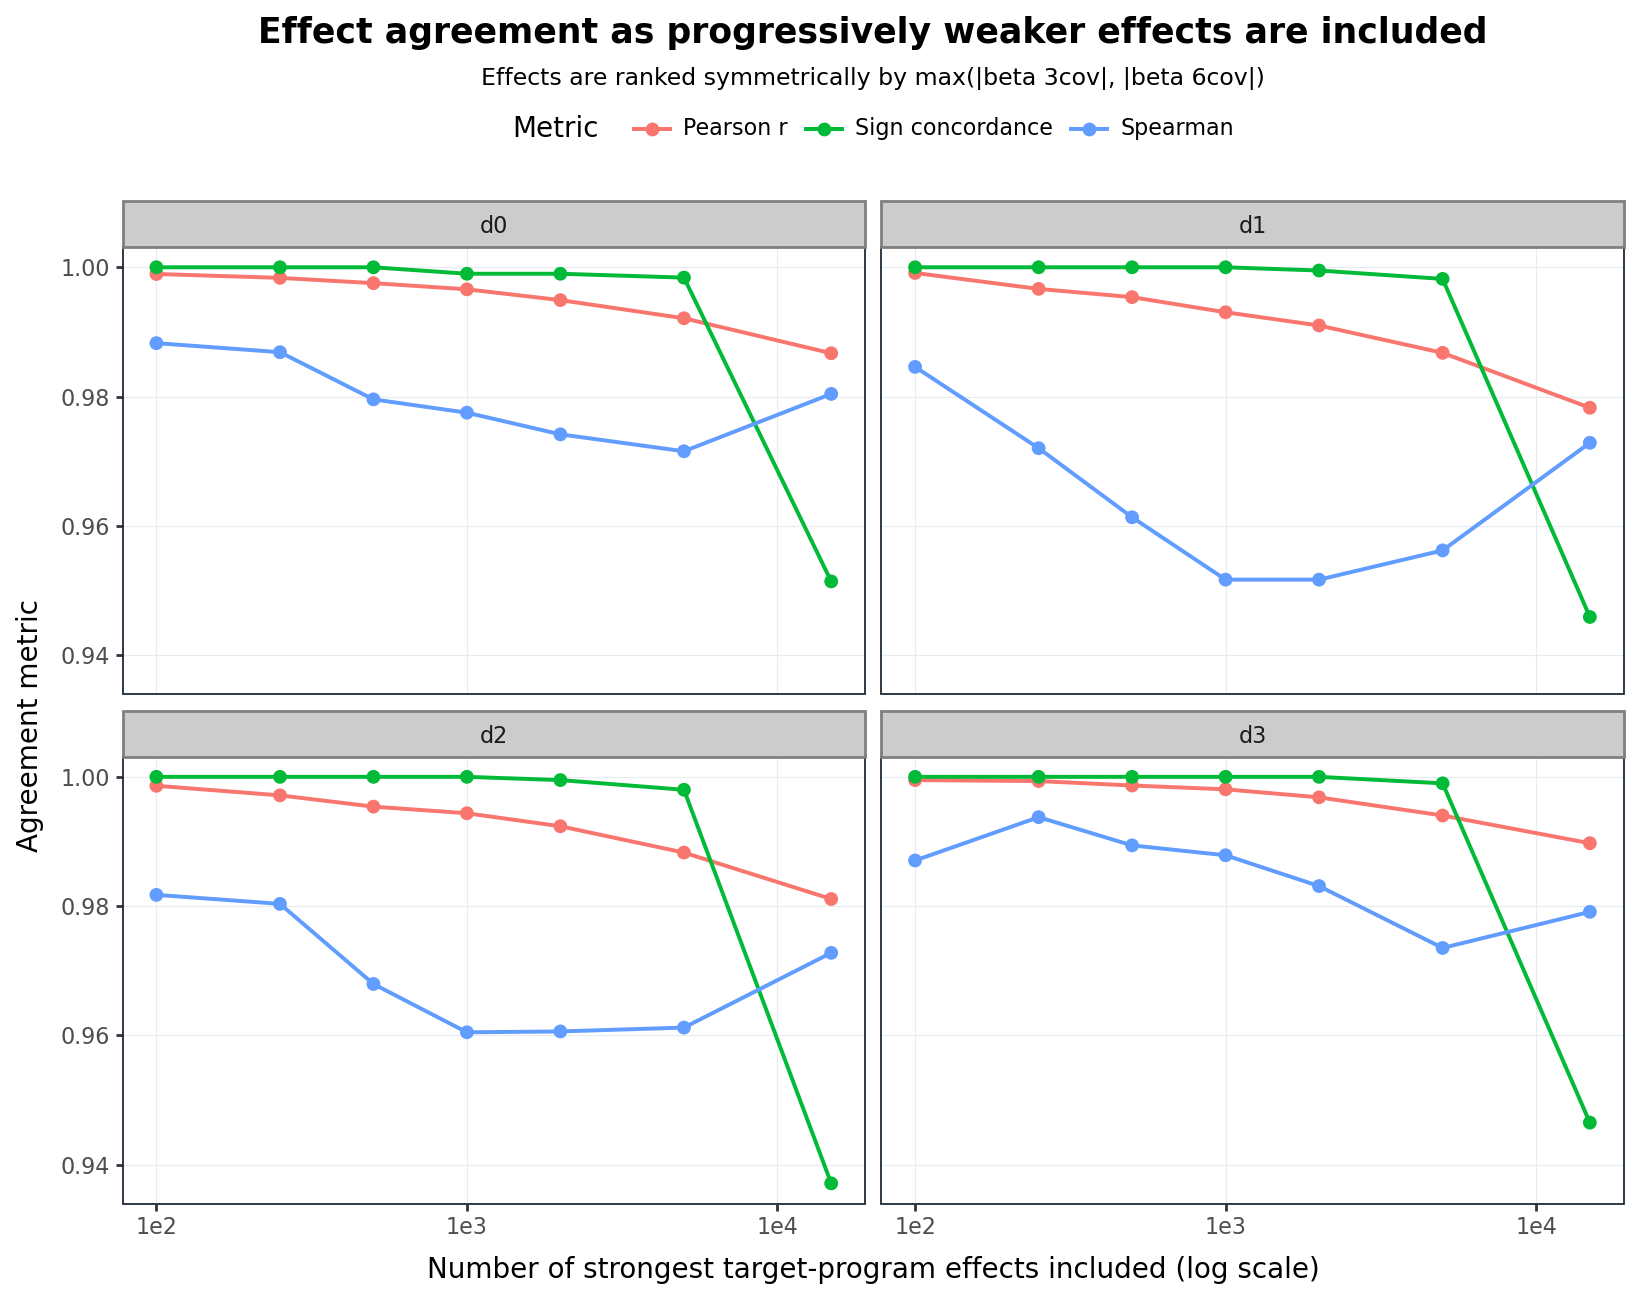

{'pdf': PosixPath('/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/QQ.sensitivity.analysis/results/ipsc_ec_3cov_vs_6cov_comparison/k_50.dt_0_2/plots/effect_agreement_by_top_n.pdf'),
 'svg': PosixPath('/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/QQ.sensitivity.analysis/results/ipsc_ec_3cov_vs_6cov_comparison/k_50.dt_0_2/plots/effect_agreement_by_top_n.svg'),
 'png': PosixPath('/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/QQ.sensitivity.analysis/results/ipsc_ec_3cov_vs_6cov_comparison/k_50.dt_0_2/plots/effect_agreement_by_top_n.png')}

In [27]:

topn_plot = topn_summary.melt(
    id_vars=["day", "top_n", "is_all_pairs"],
    value_vars=["pearson_r", "spearman_r", "sign_concordance"],
    var_name="metric_code",
    value_name="value",
)
topn_plot["metric"] = topn_plot["metric_code"].map({
    "pearson_r": "Pearson r",
    "spearman_r": "Spearman",
    "sign_concordance": "Sign concordance",
})

p_topn = (
    ggplot(topn_plot, aes("top_n", "value", color="metric", group="metric"))
    + geom_line(size=0.8)
    + geom_point(size=1.8)
    + scale_x_log10()
    + facet_wrap("~day", ncol=2)
    + labs(
        title="Effect agreement as progressively weaker effects are included",
        subtitle="Effects are ranked symmetrically by max(|beta 3cov|, |beta 6cov|)",
        x="Number of strongest target-program effects included (log scale)",
        y="Agreement metric",
        color="Metric",
    )
    + theme_bw(base_size=10)
    + theme(
        figure_size=(8.2, 6.5),
        plot_title=element_text(size=12.5, weight="bold", ha="center"),
        plot_subtitle=element_text(size=8.5, ha="center"),
        legend_position="top",
        panel_grid_major=element_line(color=GRID_COLOR, size=0.4),
        panel_grid_minor=element_blank(),
        panel_border=element_rect(color=BORDER_COLOR, size=0.65),
    )
)

display(p_topn)
save_plot(
    p_topn,
    PLOT_DIR / "effect_agreement_by_top_n",
    width=8.2,
    height=6.5,
)


## 10. Optional biological-replicate reproducibility comparison

In [28]:

def find_replicate_summary(root):
    candidates = [
        Path(root) / "biological_replicate_effects" / "plots" / "biological_replicate_DE_program_effect_correlation_summary.csv",
        Path(root) / "biological_replicate_effects" / "plots" / "DIAGNOSTIC_recomputed_summary_from_current_beta_files.csv",
    ]
    return next((path for path in candidates if path.exists()), None)

replicate_paths = {
    model: find_replicate_summary(root)
    for model, root in MODEL_ROOTS.items()
}

print("Replicate summary paths:")
for model, path in replicate_paths.items():
    print(f"  {MODEL_LABELS[model]}: {path}")

if all(path is not None for path in replicate_paths.values()):
    replicate_tables = []
    for model, path in replicate_paths.items():
        current = pd.read_csv(path)
        current["model"] = model
        current["model_label"] = MODEL_LABELS[model]
        replicate_tables.append(current)

    replicate_comparison = pd.concat(replicate_tables, ignore_index=True, sort=False)
    required = {"day", "pearson_r", "spearman_r"}
    if required.issubset(replicate_comparison.columns):
        replicate_long = replicate_comparison.melt(
            id_vars=["model", "model_label", "day"],
            value_vars=["pearson_r", "spearman_r"],
            var_name="metric_code",
            value_name="correlation",
        )
        replicate_long["metric"] = replicate_long["metric_code"].map({
            "pearson_r": "Pearson r",
            "spearman_r": "Spearman",
        })

        p_replicate = (
            ggplot(replicate_long, aes("day", "correlation", fill="model_label"))
            + geom_col(position=position_dodge(width=0.78), width=0.70)
            + scale_fill_manual(values=MODEL_COLORS, name="Model")
            + facet_wrap("~metric", nrow=1)
            + labs(
                title="Biological-replicate effect correlation by covariate model",
                x="Differentiation day",
                y="Replicate correlation",
            )
            + theme_bw(base_size=10)
            + theme(
                figure_size=(8.0, 4.3),
                plot_title=element_text(size=12.5, weight="bold", ha="center"),
                legend_position="top",
                panel_grid_major_x=element_blank(),
                panel_grid_minor=element_blank(),
                panel_border=element_rect(color=BORDER_COLOR, size=0.65),
            )
        )
        display(replicate_comparison)
        display(p_replicate)
        save_plot(
            p_replicate,
            PLOT_DIR / "biological_replicate_correlation_3cov_vs_6cov",
            width=8.0,
            height=4.3,
        )
        replicate_comparison.to_csv(
            TABLE_DIR / "biological_replicate_correlation_comparison.csv",
            index=False,
        )
    else:
        print("Replicate summary files were found but do not contain the expected correlation columns.")
else:
    print(
        "Replicate comparison skipped. It will run automatically after replicate-specific "
        "summary files exist under both model roots."
    )


Replicate summary paths:
  3 covariates: None
  6 covariates: None
Replicate comparison skipped. It will run automatically after replicate-specific summary files exist under both model roots.


## 11. Manuscript-facing summary and changed-result tables

In [ ]:

# Largest beta changes and model-specific discoveries at the primary threshold.
largest_effect_changes = (
    paired_primary
    .assign(abs_beta_change=lambda x: (x["beta_6cov"] - x["beta_3cov"]).abs())
    .sort_values(["day", "abs_beta_change"], ascending=[True, False])
    .groupby("day", sort=False)
    .head(100)
)

three_only_discoveries = paired_primary[
    paired_primary["discovery_status"] == "3 covariates only"
].sort_values(["day", "qvalue_3cov"])

six_only_discoveries = paired_primary[
    paired_primary["discovery_status"] == "6 covariates only"
].sort_values(["day", "qvalue_6cov"])

both_discoveries = paired_primary[
    paired_primary["discovery_status"] == "Both"
].sort_values(["day", "qvalue_6cov", "qvalue_3cov"])

# One row per day summarizing the central tradeoff: calibration versus result stability.
all_effect_day = effect_summary[
    effect_summary["selection"] == "all target-program pairs"
].copy()

primary_discovery_day = discovery_summary[
    (discovery_summary["pvalue_type"] == PRIMARY_PVALUE_TYPE_USED)
    & np.isclose(discovery_summary["q_cutoff"], PRIMARY_Q_CUTOFF)
].copy()

ntc_primary_wide = (
    ntc_calibration_summary[
        ntc_calibration_summary["pvalue_type"] == PRIMARY_NTC_PVALUE_TYPE_USED
    ]
    .pivot(
        index="day",
        columns="model",
        values=[
            "fraction_p_lt_0_05",
            "abs_error_at_0_05",
            "qq_rmse",
            "qq_tail_rmse",
            "ks_distance",
        ],
    )
)
ntc_primary_wide.columns = [f"{metric}_{model}" for metric, model in ntc_primary_wide.columns]
ntc_primary_wide = ntc_primary_wide.reset_index()

manuscript_summary = (
    all_effect_day.merge(
        primary_discovery_day,
        on="day",
        how="left",
        suffixes=("_effect", "_discovery"),
    )
    .merge(ntc_primary_wide, on="day", how="left")
)

selected_columns = [
    "day",
    "n_pairs",
    "pearson_r",
    "spearman_r",
    "concordance_correlation_coefficient",
    "regression_slope_6_on_3",
    "median_abs_beta_change",
    "median_abs_effect_ratio_6_over_3",
    "sign_concordance",
    "n_discoveries_3cov",
    "n_discoveries_6cov",
    "n_intersection",
    "n_3cov_only",
    "n_6cov_only",
    "jaccard",
    "sign_concordance_union",
    "fraction_p_lt_0_05_3cov",
    "fraction_p_lt_0_05_6cov",
    "abs_error_at_0_05_3cov",
    "abs_error_at_0_05_6cov",
    "qq_rmse_3cov",
    "qq_rmse_6cov",
    "qq_tail_rmse_3cov",
    "qq_tail_rmse_6cov",
    "ks_distance_3cov",
    "ks_distance_6cov",
]
selected_columns = [c for c in selected_columns if c in manuscript_summary.columns]
manuscript_summary = manuscript_summary[selected_columns]

print("Manuscript-facing model comparison summary:")
display(manuscript_summary)

print("\nLargest beta changes, first 20 rows:")
display(largest_effect_changes.head(20))

print("\nThree-covariate-only discoveries:", len(three_only_discoveries))
display(three_only_discoveries.head(20))

print("\nSix-covariate-only discoveries:", len(six_only_discoveries))
display(six_only_discoveries.head(20))

manuscript_summary.to_csv(TABLE_DIR / "manuscript_model_comparison_summary.csv", index=False)
largest_effect_changes.to_csv(TABLE_DIR / "largest_beta_changes_top100_per_day.csv", index=False)
three_only_discoveries.to_csv(TABLE_DIR / "discoveries_3cov_only.csv", index=False)
six_only_discoveries.to_csv(TABLE_DIR / "discoveries_6cov_only.csv", index=False)
both_discoveries.to_csv(TABLE_DIR / "discoveries_in_both_models.csv", index=False)

print("\nInterpretation guide")
print("--------------------")
print("1. Lower NTC abs_error_at_0_05, QQ RMSE, tail QQ RMSE, and KS distance indicate better calibration.")
print("2. Effect Pearson/Spearman quantify rank and linear stability; CCC and slope additionally detect scale attenuation or shift.")
print("3. A six/three median absolute effect ratio below 1 and a regression slope below 1 indicate overall attenuation in the six-covariate model.")
print("4. Discovery Jaccard and model-specific discovery counts quantify inferential stability.")
print("5. Inspect model-specific discoveries and the Bland-Altman plot rather than relying on one global correlation.")
print("6. This comparison identifies the aggregate impact of adding biological_sample, guide_umi_counts, and n_genes_by_counts; it does not isolate each term.")

print("\nOutput directories:")
print("  Tables:", TABLE_DIR)
print("  Plots: ", PLOT_DIR)
print("\nPDF and SVG files are the preferred Illustrator-editable outputs.")


Manuscript-facing model comparison summary:


,day,n_pairs,pearson_r,spearman_r,concordance_correlation_coefficient,regression_slope_6_on_3,median_abs_beta_change,median_abs_effect_ratio_6_over_3,sign_concordance,n_discoveries_3cov,...,fraction_p_lt_0_05_3cov,fraction_p_lt_0_05_6cov,abs_error_at_0_05_3cov,abs_error_at_0_05_6cov,qq_rmse_3cov,qq_rmse_6cov,qq_tail_rmse_3cov,qq_tail_rmse_6cov,ks_distance_3cov,ks_distance_6cov
0,d0,14900,0.986701,0.980407,0.986597,0.972423,0.013039,0.978246,0.951409,909,...,0.058689,0.059672,0.008689,0.009672,0.034047,0.033298,0.103845,0.111614,0.019583,0.020224
1,d1,14900,0.978270,0.972849,0.977761,0.947202,0.015546,0.961650,0.945906,313,...,0.057634,0.057419,0.007634,0.007419,0.025003,0.024103,0.066921,0.111614,0.014934,0.016684
2,d2,14900,0.981104,0.972772,0.980656,0.951882,0.019533,0.949295,0.937114,540,...,0.050551,0.053543,0.000551,0.003543,0.008298,0.010384,0.071362,0.085282,0.007165,0.007004
3,d3,14900,0.989733,0.979115,0.989483,0.967732,0.018212,0.973877,0.946510,1279,...,0.051355,0.055097,0.001355,0.005097,0.015856,0.032975,0.148521,0.258613,0.007520,0.016292



Largest beta changes, first 20 rows:


,day,pvalue_type,target_name,program_name,beta_3cov,pvalue_3cov,qvalue_3cov,beta_6cov,pvalue_6cov,qvalue_6cov,neglog10_p_3cov,neglog10_p_6cov,delta_neglog10_p,sign_concordant,discovery_status,union_discovery,intersection_discovery,abs_beta_change
29083,d0,empirical,VWA9,4,-0.392296,0.015798,0.184770,0.009678,0.939406,0.986862,1.801386,0.027147,-1.774240,False,Neither,False,False,0.401973
29533,d0,empirical,XRN1,4,-0.625779,0.000700,0.022237,-0.269018,0.056494,0.370659,3.154945,1.247995,-1.906950,True,3 covariates only,True,False,0.356761
19083,d0,empirical,EXOSC8,4,-0.025502,0.896910,0.980349,0.283401,0.083092,0.449715,0.047251,1.080442,1.033191,False,Neither,False,False,0.308903
16283,d0,empirical,C7orf26,4,0.025610,0.892111,0.979186,0.314883,0.009499,0.135053,0.049581,2.022320,1.972739,True,Neither,False,False,0.289274
26633,d0,empirical,SNRNP27,4,-0.290747,0.150685,0.572261,-0.002676,0.986301,0.996737,0.821930,0.005990,-0.815940,True,Neither,False,False,0.288071
23333,d0,empirical,PLRG1,4,0.275451,0.290971,0.717317,0.548078,0.007799,0.118218,0.536150,2.107949,1.571798,True,Neither,False,False,0.272627
22083,d0,empirical,MRPL32,4,-0.307576,0.123588,0.532797,-0.037526,0.779822,0.952148,0.908025,0.108005,-0.800020,True,Neither,False,False,0.270050
21533,d0,empirical,MAU2,4,-0.420576,0.009599,0.134930,-0.178912,0.121788,0.531373,2.017772,0.914396,-1.103376,True,Neither,False,False,0.241664
24983,d0,empirical,RGP1,4,-0.227842,0.177682,0.608054,0.009264,0.949805,0.989348,0.750356,0.022366,-0.727990,False,Neither,False,False,0.237106
28883,d0,empirical,UPF2,4,-0.474643,0.011499,0.151622,-0.241361,0.094791,0.476833,1.939346,1.023235,-0.916110,True,Neither,False,False,0.233282



Three-covariate-only discoveries: 306


,day,pvalue_type,target_name,program_name,beta_3cov,pvalue_3cov,qvalue_3cov,beta_6cov,pvalue_6cov,qvalue_6cov,neglog10_p_3cov,neglog10_p_6cov,delta_neglog10_p,sign_concordant,discovery_status,union_discovery,intersection_discovery
16296,d0,empirical,C7orf26,6,0.250966,0.0003,0.011951,0.164765,0.006599,0.105054,3.522922,2.180499,-1.342423,True,3 covariates only,True,False
29533,d0,empirical,XRN1,4,-0.625779,0.0007,0.022237,-0.269018,0.056494,0.370659,3.154945,1.247995,-1.906950,True,3 covariates only,True,False
25297,d0,empirical,RNF40,7,0.481823,0.0009,0.026499,0.355054,0.010699,0.145451,3.045801,1.970660,-1.075141,True,3 covariates only,True,False
17897,d0,empirical,DNAJC17,7,0.522581,0.0013,0.034586,0.421795,0.006299,0.102245,2.886100,2.200703,-0.685397,True,3 covariates only,True,False
26196,d0,empirical,SMARCA4,6,0.173361,0.0015,0.038597,0.128182,0.009399,0.133887,2.823952,2.026916,-0.797037,True,3 covariates only,True,False
28732,d0,empirical,TSTD2,39,0.512921,0.0017,0.042354,0.452720,0.007899,0.119369,2.769595,2.102416,-0.667178,True,3 covariates only,True,False
18447,d0,empirical,EIF4E,7,0.429164,0.0018,0.043819,0.297747,0.027797,0.259673,2.744771,1.555999,-1.188772,True,3 covariates only,True,False
26513,d0,empirical,SMG5,21,-0.425366,0.0018,0.043819,-0.361217,0.006399,0.103642,2.744771,2.193863,-0.550907,True,3 covariates only,True,False
22497,d0,empirical,NF2,7,0.408662,0.0019,0.045364,0.338183,0.006199,0.100841,2.721290,2.207652,-0.513638,True,3 covariates only,True,False
27048,d0,empirical,SRP68,8,-0.401059,0.0019,0.045364,-0.282386,0.010899,0.147096,2.721290,1.962617,-0.758673,True,3 covariates only,True,False



Six-covariate-only discoveries: 262


,day,pvalue_type,target_name,program_name,beta_3cov,pvalue_3cov,qvalue_3cov,beta_6cov,pvalue_6cov,qvalue_6cov,neglog10_p_3cov,neglog10_p_6cov,delta_neglog10_p,sign_concordant,discovery_status,union_discovery,intersection_discovery
17048,d0,empirical,CENPC,8,-0.481991,0.008899,0.127620,-0.568354,0.0007,0.022002,2.050653,3.154945,1.104292,True,6 covariates only,True,False
17122,d0,empirical,CHORDC1,3,-0.319641,0.009299,0.131958,-0.367014,0.0013,0.034710,2.031560,2.886100,0.854540,True,6 covariates only,True,False
18471,d0,empirical,EIF4G1,29,-0.432926,0.006499,0.104692,-0.503465,0.0013,0.034710,2.187130,2.886100,0.698970,True,6 covariates only,True,False
26560,d0,empirical,SNRNP25,19,-0.387250,0.007599,0.115422,-0.431657,0.0013,0.034710,2.119230,2.886100,0.766870,True,6 covariates only,True,False
29748,d0,empirical,ZC3H8,8,-0.361197,0.016098,0.186666,-0.417780,0.0016,0.040131,1.793218,2.795923,1.002706,True,6 covariates only,True,False
17683,d0,empirical,DBR1,4,0.318938,0.040496,0.315251,0.362632,0.0019,0.045804,1.392588,2.721290,1.328701,True,6 covariates only,True,False
16096,d0,empirical,C16orf93,6,0.196593,0.010999,0.147113,0.214749,0.0020,0.047675,1.958651,2.699013,0.740363,True,6 covariates only,True,False
18397,d0,empirical,EIF3M,7,0.396512,0.025997,0.249107,0.504363,0.0022,0.050117,1.585070,2.657621,1.072551,True,6 covariates only,True,False
16682,d0,empirical,CCNC,39,-0.383787,0.014899,0.177732,-0.477987,0.0024,0.053448,1.826857,2.619832,0.792975,True,6 covariates only,True,False
22231,d0,empirical,NAA25,38,-0.349095,0.006899,0.108553,-0.381040,0.0024,0.053448,2.161194,2.619832,0.458638,True,6 covariates only,True,False



Interpretation guide
--------------------
1. Lower NTC abs_error_at_0_05, QQ RMSE, tail QQ RMSE, and KS distance indicate better calibration.
2. Effect Pearson/Spearman quantify rank and linear stability; CCC and slope additionally detect scale attenuation or shift.
3. A six/three median absolute effect ratio below 1 and a regression slope below 1 indicate overall attenuation in the six-covariate model.
4. Discovery Jaccard and model-specific discovery counts quantify inferential stability.
5. Inspect model-specific discoveries and the Bland-Altman plot rather than relying on one global correlation.
6. This comparison identifies the aggregate impact of adding biological_sample, guide_umi_counts, and n_genes_by_counts; it does not isolate each term.

Output directories:
  Tables: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/QQ.sensitivity.analysis/results/ipsc_ec_3cov_vs_6cov_comparison/k_50.dt_0_2/tables
  Plots:  /oak/stanford/groups/engreitz/Users/tri/CodeBas

: 